# Revenue Forecasting
 

# 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import requests
from pathlib import Path
import json

from statsmodels.tsa.seasonal import seasonal_decompose, STL
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression
from statsmodels.tsa.statespace.sarimax import SARIMAX

from prophet import Prophet
from prophet.serialize import model_to_json
from sklearn.ensemble import ( RandomForestRegressor, GradientBoostingRegressor)
from xgboost import XGBRegressor


# 2. Import the cleaned daily_model table

In [2]:
df = pd.read_csv("../data_clean/daily_model_table_clean.csv",parse_dates=["date"]).reset_index(drop=True)

In [3]:
df

,date,revenue,orders,average_order_value,orders_lunch,orders_afternoon,orders_dinner,orders_dine_in,orders_delivery,orders_takeaway,...,restaurant_day_type,holiday_name,is_holiday,temperature_avg_c,temp_max_c,temp_min_c,precipitation_mm,is_rainy,weather_condition,is_promo_day
0,2024-01-01,1396.3,40,34.91,16,0,24,23,12,5,...,Quiet,New Year's Day,True,3.8,7.0,1.3,1.3,True,Rain,False
1,2024-01-02,2118.0,56,37.82,24,6,26,30,20,6,...,Quiet,NaN,False,1.3,3.6,-0.5,0.0,False,Cold,False
2,2024-01-03,1527.3,50,30.55,16,2,32,23,15,12,...,Quiet,NaN,False,3.4,5.3,1.9,7.0,True,Rain,False
3,2024-01-04,2532.3,67,37.80,20,1,46,41,17,9,...,Medium,NaN,False,5.7,6.8,4.8,1.0,True,Rain,False
4,2024-01-05,3420.7,91,37.59,21,11,59,52,31,8,...,Peak,NaN,False,-0.1,1.3,-1.2,3.3,True,Rain,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
726,2025-12-27,4453.8,106,42.02,27,10,69,72,21,13,...,Peak,NaN,False,3.1,5.6,1.0,0.0,False,Normal,False
727,2025-12-28,2529.4,67,37.75,26,5,36,33,28,6,...,Medium,NaN,False,4.8,6.2,3.7,8.9,True,Rain,False
728,2025-12-29,1468.9,43,34.16,12,1,30,25,12,6,...,Quiet,NaN,False,1.9,3.8,0.3,0.0,False,Cold,False
729,2025-12-30,2040.0,56,36.43,16,7,33,31,10,15,...,Quiet,NaN,False,-0.5,1.0,-1.7,0.0,False,Cold,False


# 3. Decomposition

In [4]:
# ============================================
# TIME SERIES DECOMPOSITION 
# CHRONOLOGICAL TRAIN / TEST SPLIT
# ============================================

# Make sure the data is sorted by date and date in datetime format,
df = df.copy()
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

# Keep the final three months as an untouched test period.
train = df.loc[df["date"] < "2025-10-01"].copy()
test = df.loc[df["date"] >= "2025-10-01"].copy()

# Set date as index and select revenue column
# STL used to guide modeling is fitted on training data only.
train_revenue = train.set_index("date")["revenue"].asfreq("D") # Make sure the frequency is daily even though our revenue is already in daily form
train_revenue.isna().sum()

np.int64(0)

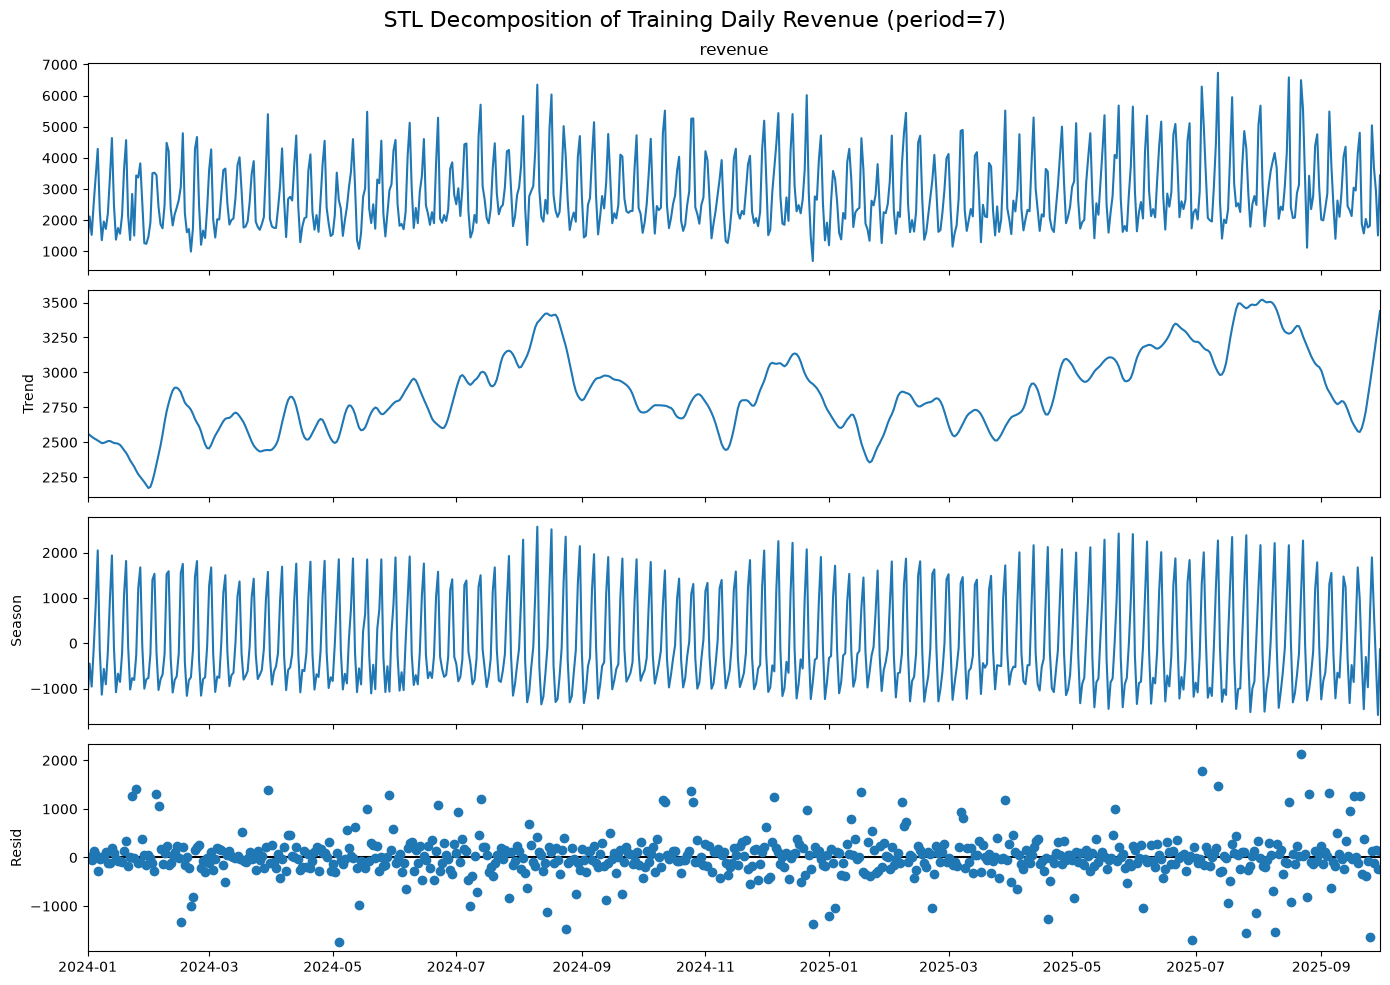

In [5]:
# Fit decomposition only on the training period to avoid using test-period patterns for model decisions.
stl = STL(
    train_revenue, 
    period=7,
    robust=True)

result = stl.fit()

fig = result.plot()
fig.set_size_inches(14, 10)
plt.suptitle("STL Decomposition of Training Daily Revenue (period=7)", fontsize=16)
plt.tight_layout()
plt.show()


STL is fitted on the training period only. STL decomposition reveals a changing underlying revenue trend and a strong weekly seasonal pattern. The seasonal component shows that revenue varies systematically across the seven-day cycle, consistent with the strong performance of the weekday-mean baseline. The residual component is mostly centered around zero but contains several large positive and negative deviations, indicating that trend and weekly seasonality do not explain all daily revenue variation. This supports testing additional predictors such as promotions, holidays and weather in the forecasting models.

In [6]:
seasonal_component = result.seasonal

seasonal_by_day = pd.DataFrame({
    "date": seasonal_component.index,
    "seasonal_effect": seasonal_component.values
})

seasonal_by_day["day_of_week"] = (
    seasonal_by_day["date"].dt.day_name()
)

seasonal_summary = (
    seasonal_by_day
    .groupby("day_of_week")["seasonal_effect"]
    .mean()
    .reindex([
        "Monday",
        "Tuesday",
        "Wednesday",
        "Thursday",
        "Friday",
        "Saturday",
        "Sunday"
    ])
)

seasonal_summary

day_of_week
Monday      -1109.524447
Tuesday      -798.206032
Wednesday    -677.668008
Thursday     -148.472746
Friday       1121.466557
Saturday     1824.104934
Sunday       -212.671212
Name: seasonal_effect, dtype: float64

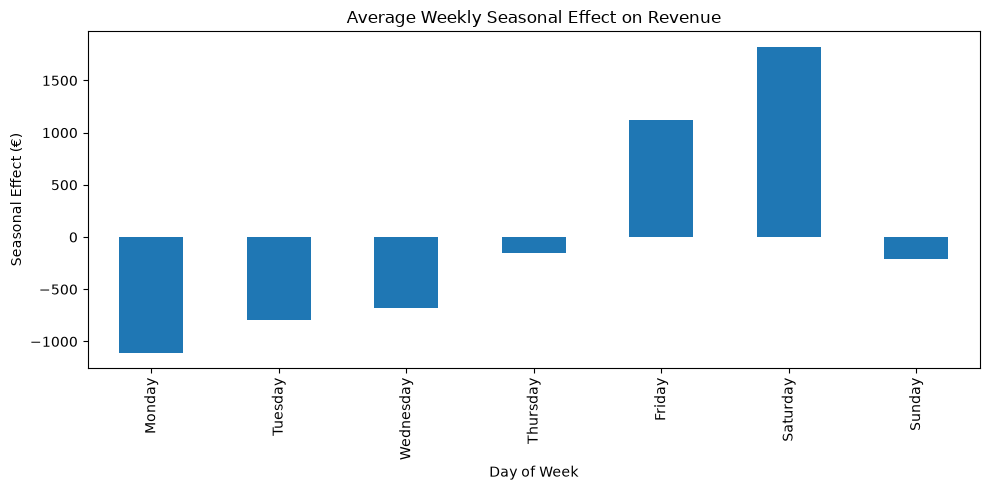

In [7]:
plt.figure(figsize=(10, 5))

seasonal_summary.plot(
    kind="bar"
)

plt.title("Average Weekly Seasonal Effect on Revenue")
plt.xlabel("Day of Week")
plt.ylabel("Seasonal Effect (€)")

plt.tight_layout()
plt.show()

### 3.1 Daily, Weekly and Monthly Revenue Patterns
The forecast target remains daily revenue. These aggregations describe the series at different time scales; they do not define separate forecasting targets or prove seasonality by themselves.

In [8]:
# ============================================
# DAILY / WEEKLY / MONTHLY REVENUE PATTERNS
# ============================================

revenue_daily = df.set_index("date")["revenue"].asfreq("D")
revenue_weekly_all = revenue_daily.resample("W-SUN").agg(["sum", "count"])
revenue_weekly = revenue_weekly_all.loc[revenue_weekly_all["count"] == 7, "sum"]
revenue_monthly = revenue_daily.resample("ME").sum()

print("Daily observations:", revenue_daily.notna().sum())
print("Complete weekly observations:", len(revenue_weekly))
print("Monthly observations:", len(revenue_monthly))
print("Final weekly bin contains", int(revenue_weekly_all["count"].iloc[-1]), "days; excluded from the complete-week plot.")


Daily observations: 731
Complete weekly observations: 104
Monthly observations: 24
Final weekly bin contains 3 days; excluded from the complete-week plot.


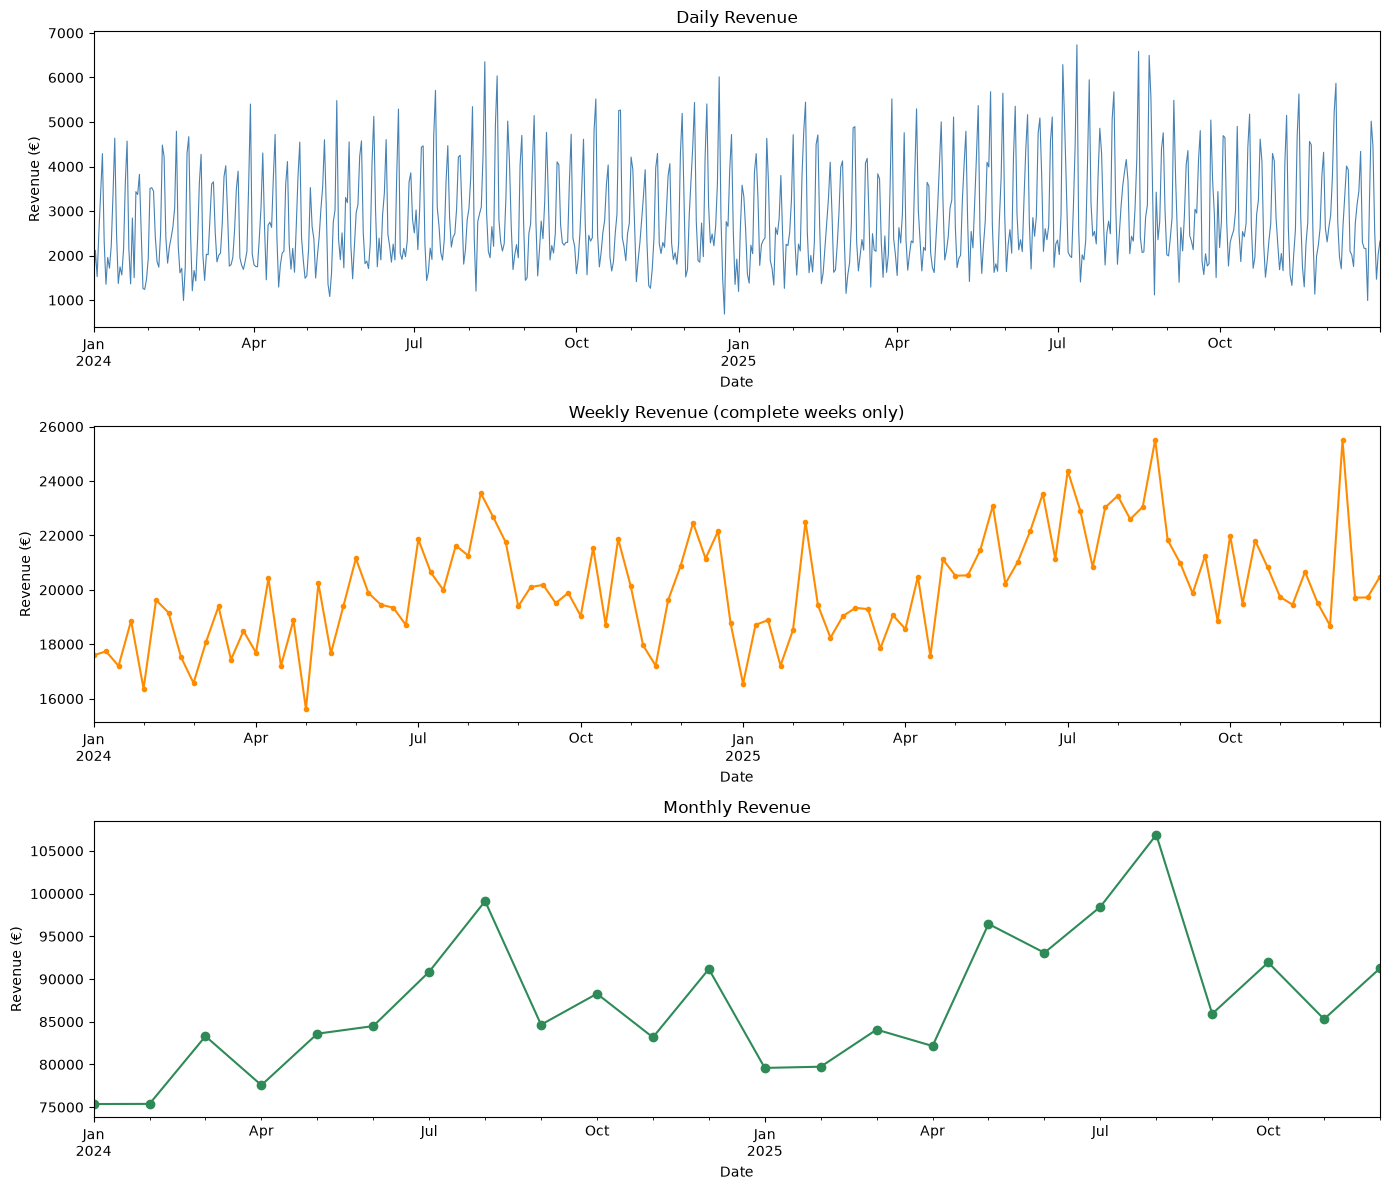

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
revenue_daily.plot(ax=axes[0], color="steelblue", linewidth=0.8)
axes[0].set(title="Daily Revenue", ylabel="Revenue (€)")
revenue_weekly.plot(ax=axes[1], color="darkorange", marker=".")
axes[1].set(title="Weekly Revenue (complete weeks only)", ylabel="Revenue (€)")
revenue_monthly.plot(ax=axes[2], color="seagreen", marker="o")
axes[2].set(title="Monthly Revenue", ylabel="Revenue (€)")
for ax in axes:
    ax.set_xlabel("Date")
plt.tight_layout()
plt.show()


Each daily point is one day’s revenue, each weekly point is a seven-day total, and each monthly point is a calendar-month total. Weekly and monthly totals naturally have larger euro values than daily revenue. Describe visible changes in level and variability; use the training-only STL and weekday baselines to assess a repeating weekly pattern. Treat the monthly plot as a broad trend description because two years provide few annual cycles.

# 4. Train/Test Split
   - chronological split
   - NO random train_test_split

In [10]:
# ============================================
# TRAIN / TEST SPLIT
# ============================================
df["date"] = pd.to_datetime(df["date"])

df = df.sort_values("date").copy()

train = df[
    df["date"] < "2025-10-01"
].copy()

test = df[
    df["date"] >= "2025-10-01"
].copy()

In [11]:
# ============================================
# CHECK TRAIN / TEST SPLIT
# ============================================

print("Training period:")
print(train["date"].min(), "to", train["date"].max())

print("\nTesting period:")
print(test["date"].min(), "to", test["date"].max())

print("\nTrain size:", len(train))
print("Test size:", len(test))

# Check for overlap
print("\nDate overlap:", len(set(train["date"]) & set(test["date"])))

# Check for missing dates
print(
    "\nMissing dates in train:",
    train["date"].diff().dt.days.dropna().ne(1).sum()
)

print(
    "Missing dates in test:",
    test["date"].diff().dt.days.dropna().ne(1).sum() # ne is not equal
)

Training period:
2024-01-01 00:00:00 to 2025-09-30 00:00:00

Testing period:
2025-10-01 00:00:00 to 2025-12-31 00:00:00

Train size: 639
Test size: 92

Date overlap: 0

Missing dates in train: 0
Missing dates in test: 0


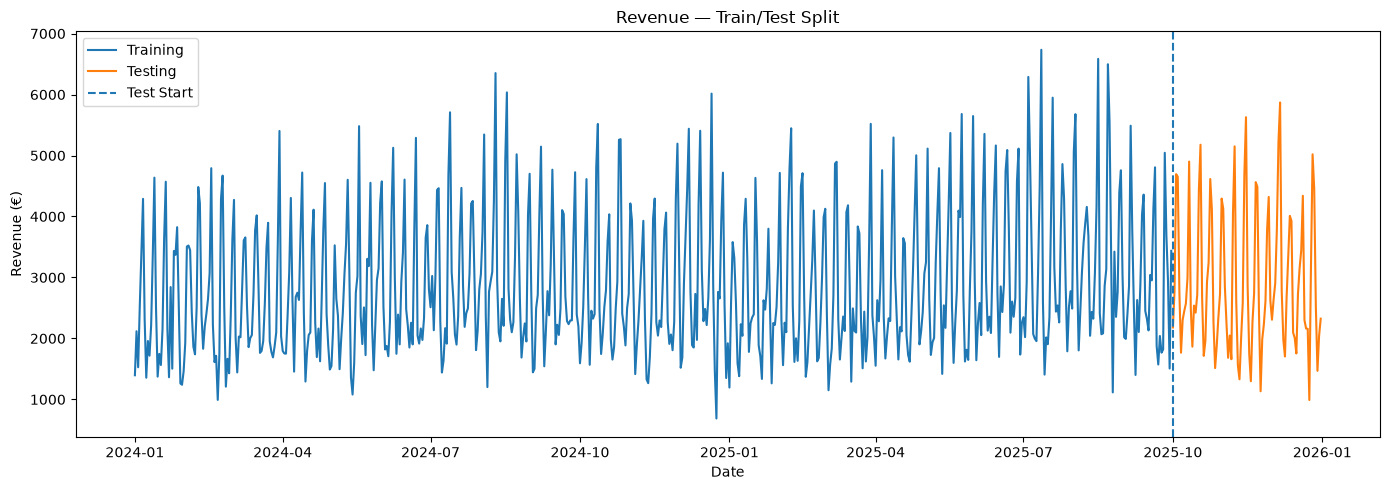

In [12]:
# ============================================
# VISUALIZE TRAIN / TEST SPLIT
# ============================================
plt.figure(figsize=(14, 5))

plt.plot(
    train["date"],
    train["revenue"],
    label="Training"
)

plt.plot(
    test["date"],
    test["revenue"],
    label="Testing"
)

plt.axvline(
    test["date"].iloc[0],
    linestyle="--",
    label="Test Start"
)

plt.title("Revenue — Train/Test Split")
plt.xlabel("Date")
plt.ylabel("Revenue (€)")
plt.legend()

plt.tight_layout()
plt.show()

# 5. Baseline Models and Rolling-Origin Validation
Compare Naive, Seasonal Naive, Mean, Recent Mean, Drift, and Weekday Mean on identical 92-day validation windows, matching the final test horizon. Each fold uses training data available only up to its origin. The final test period remains untouched.

### 5.1. Evaluation Metrics
   - MAE
   - RMSE
   - MAPE

In [13]:
# Evaluation metrics (MAPE is reported only when actual values are nonzero)
def calculate_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    nonzero = y_true != 0
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAPE (%)": np.mean(np.abs((y_true[nonzero] - y_pred[nonzero]) / y_true[nonzero])) * 100 if nonzero.any() else np.nan,
    }

validation_horizon = 30  # operational forecasting horizon used for model validation
initial_train_days = 365 # minimum history required before the first validation forecast
validation_step = 28  # move the validation origin forward by 28 days

def weekday_mean_forecast(history, forecast_dates):
    means = history.groupby(history["date"].dt.dayofweek)["revenue"].mean()
    return forecast_dates.dt.dayofweek.map(means).to_numpy(dtype=float)

def naive_forecast(history, forecast_dates):
    return np.repeat(float(history["revenue"].iloc[-1]), len(forecast_dates))

def seasonal_naive_forecast(history, forecast_dates, season_length=7):
    last_season = history["revenue"].iloc[-season_length:].to_numpy(dtype=float)
    return np.resize(last_season, len(forecast_dates))

def mean_forecast(history, forecast_dates):
    return np.repeat(float(history["revenue"].mean()), len(forecast_dates))

def recent_mean_forecast(history, forecast_dates, window=28):
    # Four recent weeks: a daily-data counterpart to a recent-period mean.
    return np.repeat(float(history["revenue"].tail(window).mean()), len(forecast_dates))

def drift_forecast(history, forecast_dates):
    values = history["revenue"].to_numpy(dtype=float)
    slope = (values[-1] - values[0]) / (len(values) - 1)
    return values[-1] + slope * np.arange(1, len(forecast_dates) + 1)

baseline_forecasters = {
    "Naive Forecast": naive_forecast,
    "Seasonal Naive": seasonal_naive_forecast,
    "Mean Forecast": mean_forecast,
    "Recent Mean Forecast": recent_mean_forecast,
    "Drift Forecast": drift_forecast,
    "Weekday Mean": weekday_mean_forecast,
}


### 5.2 Baseline Models

In [14]:
# evaluation engine
def evaluate_forecaster(forecaster, train_data, horizon, initial_days, step, model_name="Model"):
    data = train_data.sort_values("date").reset_index(drop=True)
    rows = []
    for origin in range(initial_days, len(data) - horizon + 1, step):
        history = data.iloc[:origin].copy()
        valid = data.iloc[origin:origin + horizon].copy()
        pred = forecaster(history, valid["date"])
        row = {"model": model_name, "origin": history["date"].iloc[-1]}
        row.update(calculate_metrics(valid["revenue"].to_numpy(), pred))
        rows.append(row)
    return pd.DataFrame(rows)

# baseline validation
baseline_folds = pd.concat([
    evaluate_forecaster(fn, train, validation_horizon, initial_train_days, validation_step, name)
    for name, fn in baseline_forecasters.items()
], ignore_index=True)

baseline_summary = (baseline_folds.groupby("model")[["MAE", "RMSE", "MAPE (%)"]]
                    .agg(["mean", "std"]).round(2))
baseline_summary


MAE             RMSE         MAPE (%)      
                         mean     std     mean     std     mean   std
model                                                                
Drift Forecast        1350.26  221.95  1757.92  237.06    39.39  6.07
Mean Forecast          919.95   81.74  1176.34  171.94    33.41  4.36
Naive Forecast        1354.16  220.44  1761.41  236.76    39.50  5.95
Recent Mean Forecast   951.67  102.94  1170.08  137.38    36.12  5.43
Seasonal Naive         552.67  143.72   717.66  173.68    19.76  5.02
Weekday Mean           429.43   93.07   559.83  150.79    14.76  2.23

Lower MAE/RMSE/MAPE indicates smaller errors; MAE is the primary selection metric because it is in euros/dollar and easier to interpret. The fold standard deviation shows how much performance varies across time.

Baseline benchmark
────────────────────────
* Weekday Mean
  
- MAE   = €429.43
- RMSE  = €559.83
- MAPE  = 14.76 %

# 6. Traditional Forecasting Models

In [15]:
# Moving Average: use the previous 7 days to forecast the next day, then recursively forecasts the remaining days
def moving_average_forecast(history, forecast_dates, window=7):
    values = list(history["revenue"].astype(float))
    predictions = []
    for _ in forecast_dates:
        prediction = float(np.mean(values[-window:]))
        predictions.append(prediction)
        values.append(prediction)
    return np.asarray(predictions)

# Auto Regressive forecast
def ar_forecast(history, forecast_dates, lags=7):
    # A linear autoregression fitted on the seven prior daily revenue values.
    values = history.sort_values("date")["revenue"].to_numpy(dtype=float)
    X = np.array([values[t - lags:t][::-1] for t in range(lags, len(values))])
    y = values[lags:]
    fitted = LinearRegression().fit(X, y)
    predictions = []
    history_values = list(values)
    for _ in forecast_dates:
        prediction = float(fitted.predict(np.array(history_values[-lags:][::-1]).reshape(1, -1))[0])
        predictions.append(prediction)
        history_values.append(prediction)
    return np.asarray(predictions)

# ARIMA
def arima_forecast(history, forecast_dates):
    # ARIMA(1,0,1): the non-seasonal version of the state-space model.
    y = history.set_index("date")["revenue"].asfreq("D") # makes the series explicitly daily
    model = SARIMAX(y, order=(1, 0, 1), trend="t", # "t" adds a linear time trend
                    enforce_stationarity=False, enforce_invertibility=False)
    fitted = model.fit(disp=False, maxiter=100)
    return np.asarray(fitted.forecast(steps=len(forecast_dates)), dtype=float)

# SARIMA
def sarima_forecast(history, forecast_dates):
    y = history.set_index("date")["revenue"].asfreq("D")
    model = SARIMAX(y, order=(1, 0, 1), seasonal_order=(1, 0, 1, 7),
                    enforce_stationarity=False, enforce_invertibility=False)
    fitted = model.fit(disp=False, maxiter=100)
    return np.asarray(fitted.forecast(steps=len(forecast_dates)), dtype=float)

# Put the traditional models into a dictionary
traditional_forecasters = {
    "Moving Average — 7 Days": moving_average_forecast,
    "AR — 7 Lags": ar_forecast,
    "ARIMA (1,0,1)": arima_forecast,
    "SARIMA — Weekly": sarima_forecast,
}

# Run rolling validation
traditional_folds = pd.concat([
    evaluate_forecaster(fn, train, validation_horizon, initial_train_days, validation_step, name)
    for name, fn in traditional_forecasters.items()
], ignore_index=True)
traditional_summary = (traditional_folds.groupby("model")[["MAE", "RMSE", "MAPE (%)"]].agg(["mean", "std"]).round(2))
traditional_summary
                       


MAE             RMSE         MAPE (%)       
                            mean     std     mean     std     mean    std
model                                                                    
AR — 7 Lags               526.05   76.73   703.82  144.57    18.65   2.42
ARIMA (1,0,1)            1566.72  120.49  1781.03  132.91    71.93  11.71
Moving Average — 7 Days   930.90  132.35  1160.66  150.35    34.59   5.19
SARIMA — Weekly           407.98   70.47   532.29  116.66    14.87   3.60

# 7. Baseline vs Traditional

In [16]:
baseline_validation_summary = (
    baseline_folds
    .groupby("model")[["MAE", "RMSE", "MAPE (%)"]]
    .mean()
    .reset_index()
)

traditional_validation_summary = (
    traditional_folds
    .groupby("model")[["MAE", "RMSE", "MAPE (%)"]]
    .mean()
    .reset_index()
)

validation_comparison = pd.concat(
    [
        baseline_validation_summary,
        traditional_validation_summary
    ],
    ignore_index=True
)

validation_comparison = (
    validation_comparison
    .sort_values("MAE")
    .reset_index(drop=True)
)

validation_comparison.round(2)

,model,MAE,RMSE,MAPE (%)
0,SARIMA — Weekly,407.98,532.29,14.87
1,Weekday Mean,429.43,559.83,14.76
2,AR — 7 Lags,526.05,703.82,18.65
3,Seasonal Naive,552.67,717.66,19.76
4,Mean Forecast,919.95,1176.34,33.41
5,Moving Average — 7 Days,930.90,1160.66,34.59
6,Recent Mean Forecast,951.67,1170.08,36.12
7,Drift Forecast,1350.26,1757.92,39.39
8,Naive Forecast,1354.16,1761.41,39.50
9,"ARIMA (1,0,1)",1566.72,1781.03,71.93


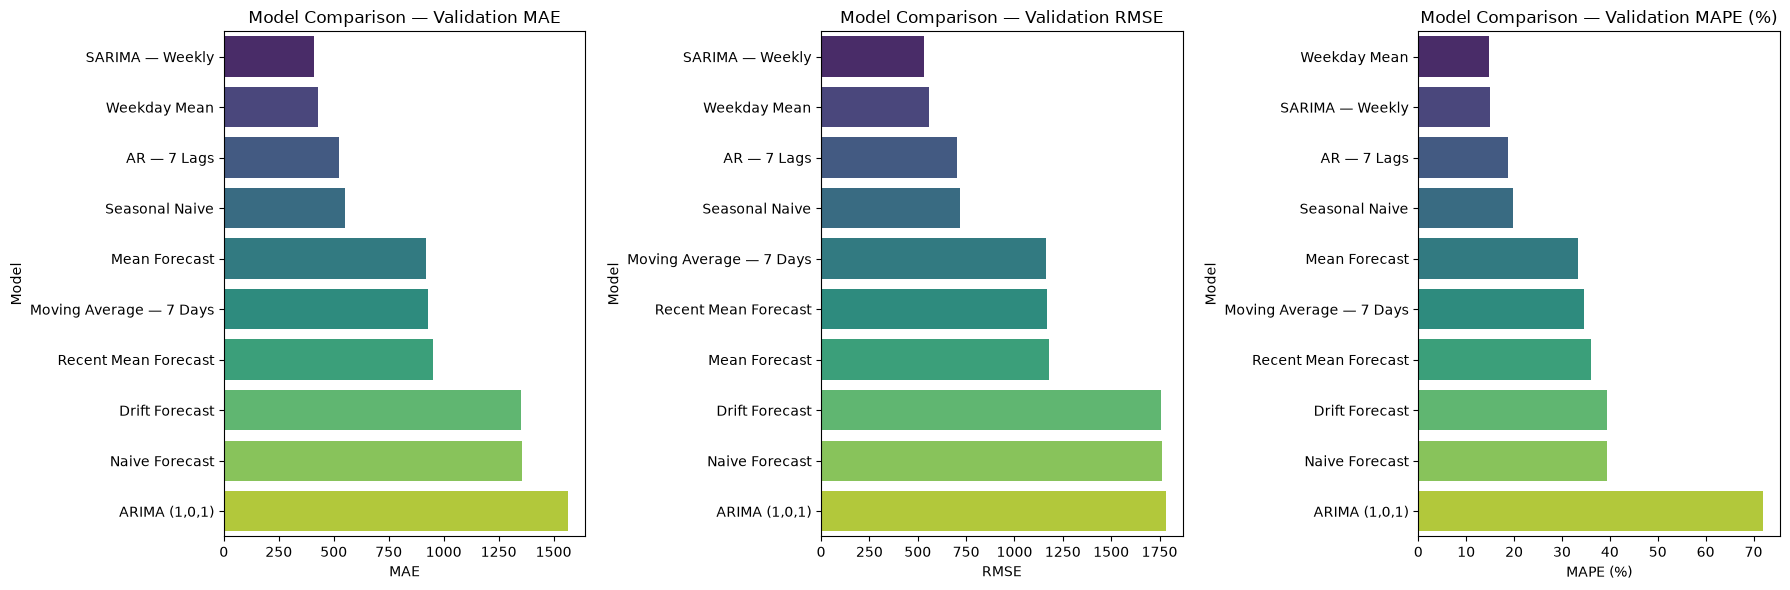

In [17]:
# ============================================
# VISUALIZE Model Comparision
# ============================================
metrics = [
    "MAE",
    "RMSE",
    "MAPE (%)"
]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6)
)

for ax, metric in zip(axes, metrics):

    plot_data = (
        validation_comparison
        .sort_values(metric)
    )

    sns.barplot(
        data=plot_data,
        x=metric,
        y="model",
        hue="model",
        legend=False,
        palette="viridis",
        ax=ax
    )

    ax.set_title(
        f"Model Comparison — Validation {metric}"
    )

    ax.set_xlabel(metric)
    ax.set_ylabel("Model")

plt.tight_layout()
plt.show()

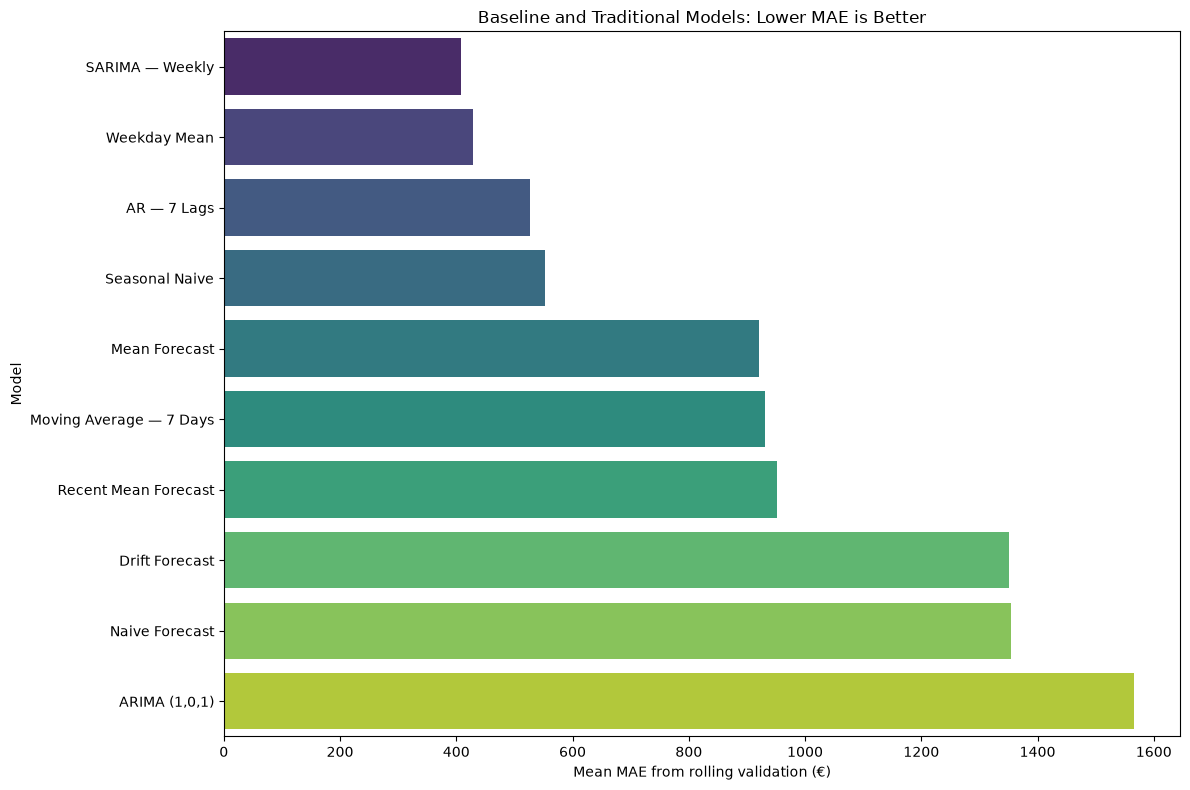

In [18]:
# ============================================
# VISUALIZE Model Comparision with MAE metrics
# ============================================

all_folds = pd.concat([baseline_folds, traditional_folds], ignore_index=True)
model_comparison = (all_folds.groupby("model")[["MAE", "RMSE", "MAPE (%)"]]
                    .agg(["mean", "std"]))
model_comparison.columns = [f"{metric}_{stat}" for metric, stat in model_comparison.columns]
model_comparison = model_comparison.sort_values("MAE_mean").round(2)

comparison_table = (model_comparison.reset_index()
                    .rename(columns={
                        "model": "Model",
                        "MAE_mean": "MAE (€)",
                        "RMSE_mean": "RMSE (€)",
                        "MAPE (%)_mean": "MAPE (%)",
                        "MAE_std": "MAE SD (€)",
                        "RMSE_std": "RMSE SD (€)",
                        "MAPE (%)_std": "MAPE SD (%)",
                    }))

plt.figure(figsize=(12, 8))
sns.barplot(
    data=comparison_table.sort_values("MAE (€)"),
    x="MAE (€)",
    y="Model",
    hue="Model",
    legend=False,
    palette="viridis"
)
plt.title("Baseline and Traditional Models: Lower MAE is Better")
plt.xlabel("Mean MAE from rolling validation (€)")
plt.ylabel("Model")
plt.tight_layout()
plt.show()


MAE was selected as the primary evaluation metric because it provides an interpretable measure of average daily revenue error in euros. RMSE was used as a secondary metric to account for larger forecasting errors, while MAPE was used as a supporting percentage-based metric. Based on rolling-origin validation, SARIMA achieved the lowest MAE and RMSE, while Weekday Mean achieved a marginally lower MAPE. Therefore, ```SARIMA-weekly was considered the stronger model at this stage.```

## 6. Prophet

This notebook compares a revenue-only Prophet model with a weekly-seasonality Prophet model. Weather, holiday, calendar, and promotion inputs are tested in the dedicated external-feature models later in the notebook.

In [19]:
# baseline prophet 
def prophet_forecast(history, forecast_dates, weekly_seasonality=False):
    ptrain = history[["date", "revenue"]].rename(columns={"date": "ds", "revenue": "y"})
    model = Prophet(
        weekly_seasonality=weekly_seasonality,
        yearly_seasonality=False,  # under two years of training history: avoid unstable annual seasonality
        daily_seasonality=False,
        seasonality_mode="additive",
        interval_width=0.80,
    )
    model.fit(ptrain)
    future = pd.DataFrame({"ds": pd.to_datetime(forecast_dates)})
    forecast = model.predict(future)
    return forecast["yhat"].to_numpy()

def prophet_revenue_only(history, dates):
    return prophet_forecast(history, dates, weekly_seasonality=False)

def prophet_weekly(history, dates):
    return prophet_forecast(history, dates, weekly_seasonality=True)

# Evaluate both
prophet_folds = pd.concat([
    evaluate_forecaster(prophet_revenue_only, train, validation_horizon, initial_train_days, validation_step, "Prophet — Revenue Only"),
    evaluate_forecaster(prophet_weekly, train, validation_horizon, initial_train_days, validation_step, "Prophet — Weekly Seasonality"),
], ignore_index=True)

prophet_folds.groupby("model")[["MAE", "RMSE", "MAPE (%)"]].agg(["mean", "std"]).round(2)


12:02:08 - cmdstanpy - INFO - Chain [1] start processing
12:02:08 - cmdstanpy - INFO - Chain [1] done processing
12:02:08 - cmdstanpy - INFO - Chain [1] start processing
12:02:08 - cmdstanpy - INFO - Chain [1] done processing
12:02:08 - cmdstanpy - INFO - Chain [1] start processing
12:02:08 - cmdstanpy - INFO - Chain [1] done processing
12:02:08 - cmdstanpy - INFO - Chain [1] start processing
12:02:08 - cmdstanpy - INFO - Chain [1] done processing
12:02:08 - cmdstanpy - INFO - Chain [1] start processing
12:02:08 - cmdstanpy - INFO - Chain [1] done processing
12:02:08 - cmdstanpy - INFO - Chain [1] start processing
12:02:09 - cmdstanpy - INFO - Chain [1] done processing
12:02:09 - cmdstanpy - INFO - Chain [1] start processing
12:02:09 - cmdstanpy - INFO - Chain [1] done processing
12:02:09 - cmdstanpy - INFO - Chain [1] start processing
12:02:09 - cmdstanpy - INFO - Chain [1] done processing
12:02:09 - cmdstanpy - INFO - Chain [1] start processing
12:02:09 - cmdstanpy - INFO - Chain [1]

MAE            RMSE         MAPE (%)      
                                mean    std     mean     std     mean   std
model                                                                      
Prophet — Revenue Only        957.70  74.90  1174.79  139.24    36.68  5.77
Prophet — Weekly Seasonality  418.27  63.72   538.31  110.58    14.94  2.92

Prophet with Revenue + Calendar

In [20]:
def prophet_external_forecast(
    history,
    valid,
    regressors,
    weekly_seasonality=True
):
    train_prophet = (
        history[["date", "revenue"] + regressors]
        .rename(
            columns={
                "date": "ds",
                "revenue": "y"
            }
        )
    )

    valid_prophet = (
        valid[["date"] + regressors]
        .rename(columns={"date": "ds"})
    )

    model = Prophet(
        weekly_seasonality=weekly_seasonality,
        yearly_seasonality=False,
        daily_seasonality=False,
        seasonality_mode="additive",
        interval_width=0.80,
    )

    for regressor in regressors:
        model.add_regressor(regressor)

    model.fit(train_prophet)

    forecast = model.predict(valid_prophet)

    return forecast["yhat"].to_numpy()


In [21]:
# prophet evaluate function
def evaluate_prophet_external(
    forecaster,
    train_data,
    horizon,
    initial_days,
    step,
    model_name="Model"
):
    data = (
        train_data
        .sort_values("date")
        .reset_index(drop=True)
    )

    rows = []

    for origin in range(
        initial_days,
        len(data) - horizon + 1,
        step
    ):

        history = data.iloc[:origin].copy()

        valid = data.iloc[
            origin:origin + horizon
        ].copy()

        pred = forecaster(
            history,
            valid
        )

        row = {
            "model": model_name,
            "origin": history["date"].iloc[-1]
        }

        row.update(
            calculate_metrics(
                valid["revenue"].to_numpy(),
                pred
            )
        )

        rows.append(row)

    return pd.DataFrame(rows)

In [22]:
calendar_regressors = [
    "is_holiday",
    "is_promo_day"
]

def prophet_calendar(
    history,
    valid
):
    return prophet_external_forecast(
        history,
        valid,
        regressors=calendar_regressors,
        weekly_seasonality=True
    )

In [23]:
# Evaluate the model Prophet — Revenue + Calendar
prophet_calendar_folds = evaluate_prophet_external(
    prophet_calendar,
    train,
    validation_horizon,
    initial_train_days,
    validation_step,
    "Prophet — Revenue + Calendar"
)

prophet_calendar_summary = (
    prophet_calendar_folds
    .groupby("model")[["MAE", "RMSE", "MAPE (%)"]]
    .agg(["mean", "std"])
    .round(2)
)

prophet_calendar_summary

12:02:10 - cmdstanpy - INFO - Chain [1] start processing
12:02:10 - cmdstanpy - INFO - Chain [1] done processing
12:02:10 - cmdstanpy - INFO - Chain [1] start processing
12:02:10 - cmdstanpy - INFO - Chain [1] done processing
12:02:10 - cmdstanpy - INFO - Chain [1] start processing
12:02:10 - cmdstanpy - INFO - Chain [1] done processing
12:02:10 - cmdstanpy - INFO - Chain [1] start processing
12:02:10 - cmdstanpy - INFO - Chain [1] done processing
12:02:10 - cmdstanpy - INFO - Chain [1] start processing
12:02:10 - cmdstanpy - INFO - Chain [1] done processing
12:02:10 - cmdstanpy - INFO - Chain [1] start processing
12:02:10 - cmdstanpy - INFO - Chain [1] done processing
12:02:10 - cmdstanpy - INFO - Chain [1] start processing
12:02:10 - cmdstanpy - INFO - Chain [1] done processing
12:02:10 - cmdstanpy - INFO - Chain [1] start processing
12:02:10 - cmdstanpy - INFO - Chain [1] done processing
12:02:10 - cmdstanpy - INFO - Chain [1] start processing
12:02:10 - cmdstanpy - INFO - Chain [1]

MAE          RMSE         MAPE (%)      
                                mean    std   mean     std     mean   std
model                                                                    
Prophet — Revenue + Calendar  418.53  60.52  544.5  105.74    14.96  3.53

Prophet with Revenue + Calendar + Weather

In [24]:
calendar_weather_regressors = [
    "is_weekend",
    "is_holiday",
    "is_promo_day",
    "temperature_avg_c",
    "precipitation_mm",
    "is_rainy"
]

def prophet_calendar_weather(
    history,
    valid
):
    return prophet_external_forecast(
        history,
        valid,
        regressors=calendar_weather_regressors,
        weekly_seasonality=True
    )

# Evaluate model Prophet — Calendar + Weather
prophet_weather_folds = evaluate_prophet_external(
    prophet_calendar_weather,
    train,
    validation_horizon,
    initial_train_days,
    validation_step,
    "Prophet — Calendar + Weather"
)

prophet_weather_summary = (
    prophet_weather_folds
    .groupby("model")[["MAE", "RMSE", "MAPE (%)"]]
    .agg(["mean", "std"])
    .round(2)
)

prophet_weather_summary

12:02:10 - cmdstanpy - INFO - Chain [1] start processing
12:02:10 - cmdstanpy - INFO - Chain [1] done processing
12:02:10 - cmdstanpy - INFO - Chain [1] start processing
12:02:10 - cmdstanpy - INFO - Chain [1] done processing
12:02:10 - cmdstanpy - INFO - Chain [1] start processing
12:02:10 - cmdstanpy - INFO - Chain [1] done processing
12:02:11 - cmdstanpy - INFO - Chain [1] start processing
12:02:11 - cmdstanpy - INFO - Chain [1] done processing
12:02:11 - cmdstanpy - INFO - Chain [1] start processing
12:02:11 - cmdstanpy - INFO - Chain [1] done processing
12:02:11 - cmdstanpy - INFO - Chain [1] start processing
12:02:11 - cmdstanpy - INFO - Chain [1] done processing
12:02:11 - cmdstanpy - INFO - Chain [1] start processing
12:02:11 - cmdstanpy - INFO - Chain [1] done processing
12:02:11 - cmdstanpy - INFO - Chain [1] start processing
12:02:11 - cmdstanpy - INFO - Chain [1] done processing
12:02:11 - cmdstanpy - INFO - Chain [1] start processing
12:02:11 - cmdstanpy - INFO - Chain [1]

MAE          RMSE         MAPE (%)      
                                mean    std   mean     std     mean   std
model                                                                    
Prophet — Calendar + Weather  400.86  68.29  525.2  115.97    14.85  4.17

Compare all four Prophet models

In [25]:
prophet_all_folds = pd.concat(
    [
        prophet_folds,
        prophet_calendar_folds,
        prophet_weather_folds
    ],
    ignore_index=True
)

prophet_all_summary = (
    prophet_all_folds
    .groupby("model")[[
        "MAE",
        "RMSE",
        "MAPE (%)"
    ]]
    .agg(["mean", "std"])
    .round(2)
)

prophet_all_summary

MAE            RMSE         MAPE (%)      
                                mean    std     mean     std     mean   std
model                                                                      
Prophet — Calendar + Weather  400.86  68.29   525.20  115.97    14.85  4.17
Prophet — Revenue + Calendar  418.53  60.52   544.50  105.74    14.96  3.53
Prophet — Revenue Only        957.70  74.90  1174.79  139.24    36.68  5.77
Prophet — Weekly Seasonality  418.27  63.72   538.31  110.58    14.94  2.92

Create a clean Prophet comparison table

In [26]:
prophet_comparison = (
    prophet_all_folds
    .groupby("model")[[
        "MAE",
        "RMSE",
        "MAPE (%)"
    ]]
    .mean()
    .sort_values("MAE")
    .round(2)
)

prophet_comparison

,MAE,RMSE,MAPE (%)
model,,,
Prophet — Calendar + Weather,400.86,525.20,14.85
Prophet — Weekly Seasonality,418.27,538.31,14.94
Prophet — Revenue + Calendar,418.53,544.50,14.96
Prophet — Revenue Only,957.70,1174.79,36.68


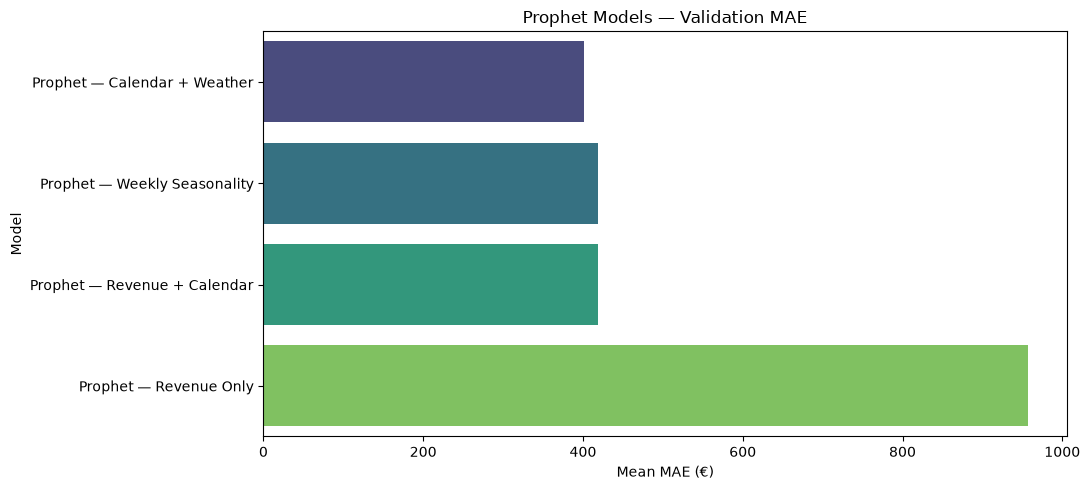

In [27]:
# ============================================
# VISUALIZE Prophet Models comparision
# ============================================
plot_data = (
    prophet_comparison
    .reset_index()
    .sort_values("MAE")
)

plt.figure(figsize=(11, 5))

sns.barplot(
    data=plot_data,
    x="MAE",
    y="model",
    hue="model",
    legend=False,
    palette="viridis"
)

plt.title("Prophet Models — Validation MAE")
plt.xlabel("Mean MAE (€)")
plt.ylabel("Model")

plt.tight_layout()
plt.show()

For now, `Prophet with Calendar + Weather` is currently the best model, but only by €7.12 MAE versus SARIMA-weekly.

# 7. SARIMAX

In [28]:
def make_sarimax_exog(dates):
    dates = pd.DatetimeIndex(dates)
    return pd.DataFrame({
        "is_weekend": (dates.dayofweek >= 5).astype(int),
        "annual_sin": np.sin(2 * np.pi * dates.dayofyear / 365.25),
        "annual_cos": np.cos(2 * np.pi * dates.dayofyear / 365.25),
    }, index=dates)

def sarimax_forecast(history, forecast_dates):
    y = history.set_index("date")["revenue"].asfreq("D")
    train_exog = make_sarimax_exog(y.index)
    future_exog = make_sarimax_exog(pd.to_datetime(forecast_dates))
    model = SARIMAX(y, exog=train_exog, order=(1, 0, 1), seasonal_order=(1, 0, 1, 7),
                    enforce_stationarity=False, enforce_invertibility=False)
    fitted = model.fit(disp=False, maxiter=100)
    return np.asarray(fitted.forecast(steps=len(forecast_dates), exog=future_exog), dtype=float)

sarimax_folds = evaluate_forecaster(sarimax_forecast, train, validation_horizon,
                                    initial_train_days, validation_step, "SARIMAX — Calendar + Weekly")
sarimax_summary = (sarimax_folds.groupby("model")[["MAE", "RMSE", "MAPE (%)"]].agg(["mean", "std"]).round(2))
sarimax_summary


/opt/anaconda3/envs/restrodine-env/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/opt/anaconda3/envs/restrodine-env/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/opt/anaconda3/envs/restrodine-env/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


MAE           RMSE         MAPE (%)      
                               mean    std    mean     std     mean   std
model                                                                    
SARIMAX — Calendar + Weekly  432.96  72.99  563.79  108.44    14.74  2.06

### ALL Models comparison

In [29]:
pre_ml_comparison = pd.concat(
    [
        baseline_folds,
        traditional_folds,
        prophet_all_folds,
        sarimax_folds
    ],
    ignore_index=True
)

pre_ml_leaderboard = (
    pre_ml_comparison
    .groupby("model")[["MAE", "RMSE", "MAPE (%)"]]
    .mean()
    .sort_values("MAE")
    .round(2)
)

pre_ml_leaderboard

,MAE,RMSE,MAPE (%)
model,,,
Prophet — Calendar + Weather,400.86,525.20,14.85
SARIMA — Weekly,407.98,532.29,14.87
Prophet — Weekly Seasonality,418.27,538.31,14.94
Prophet — Revenue + Calendar,418.53,544.50,14.96
Weekday Mean,429.43,559.83,14.76
SARIMAX — Calendar + Weekly,432.96,563.79,14.74
AR — 7 Lags,526.05,703.82,18.65
Seasonal Naive,552.67,717.66,19.76
Mean Forecast,919.95,1176.34,33.41


In [30]:
pre_ml_stability = (
    pre_ml_comparison
    .groupby("model")[["MAE", "RMSE", "MAPE (%)"]]
    .std()
    .sort_values("MAE")
    .round(2)
)

pre_ml_stability

,MAE,RMSE,MAPE (%)
model,,,
Prophet — Revenue + Calendar,60.52,105.74,3.53
Prophet — Weekly Seasonality,63.72,110.58,2.92
Prophet — Calendar + Weather,68.29,115.97,4.17
SARIMA — Weekly,70.47,116.66,3.60
SARIMAX — Calendar + Weekly,72.99,108.44,2.06
Prophet — Revenue Only,74.90,139.24,5.77
AR — 7 Lags,76.73,144.57,2.42
Mean Forecast,81.74,171.94,4.36
Weekday Mean,93.07,150.79,2.23


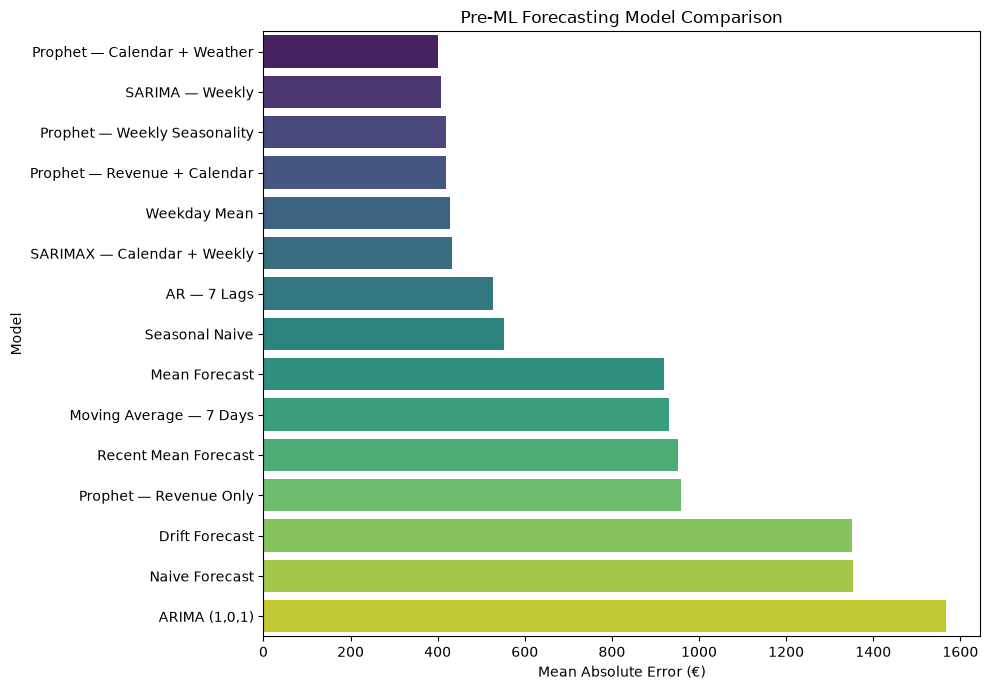

In [31]:
# ================================================
# VISUALIZE All Model Comparision with MAE metrics
# ================================================
plot_data = (
    pre_ml_leaderboard
    .reset_index()
    .sort_values("MAE", ascending=True)
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=plot_data,
    x="MAE",
    y="model",
    hue="model",
    palette="viridis"
)

plt.title("Pre-ML Forecasting Model Comparison")
plt.xlabel("Mean Absolute Error (€)")
plt.ylabel("Model")
plt.tight_layout()
plt.show()

`Prophet Calendar + Weather` is currently the best model.

# 8. Random Forest

In [32]:

LAGS = [1, 7, 14, 28]
def make_calendar_features(dates):
    dates = pd.DatetimeIndex(dates)
    return pd.DataFrame({
        "dow": dates.dayofweek,
        "month": dates.month,
        "dayofyear_sin": np.sin(2 * np.pi * dates.dayofyear / 365.25),
        "dayofyear_cos": np.cos(2 * np.pi * dates.dayofyear / 365.25),
        "is_weekend": (dates.dayofweek >= 5).astype(int),
    }, index=dates)

def make_rf_training(history):
    y = history.set_index("date")["revenue"].asfreq("D")
    feats = make_calendar_features(y.index)
    for lag in LAGS:
        feats[f"lag_{lag}"] = y.shift(lag)
    feats["rolling_mean_7"] = y.shift(1).rolling(7).mean()
    data = feats.join(y.rename("target")).dropna()
    return data.drop(columns="target"), data["target"]

def random_forest_forecast(history, forecast_dates):
    X, y = make_rf_training(history)
    model = RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                                  max_features=0.8, random_state=42, n_jobs=-1)
    model.fit(X, y)
    history_values = list(history.sort_values("date")["revenue"].astype(float))
    preds = []
    for date in pd.to_datetime(forecast_dates):
        row = make_calendar_features([date]).iloc[0].to_dict()
        for lag in LAGS:
            row[f"lag_{lag}"] = history_values[-lag]
        row["rolling_mean_7"] = float(np.mean(history_values[-7:]))
        pred = float(model.predict(pd.DataFrame([row], columns=X.columns))[0])
        preds.append(pred)
        history_values.append(pred)
    return np.asarray(preds)

rf_folds = evaluate_forecaster(random_forest_forecast, train, validation_horizon,
                               initial_train_days, validation_step, "Random Forest — Lag + Calendar")
rf_folds[["model", "origin", "MAE", "RMSE", "MAPE (%)"]]

rf_summary = (
    rf_folds
    .groupby("model")[["MAE", "RMSE", "MAPE (%)"]]
    .agg(["mean", "std"])
    .round(2)
)

rf_summary


MAE           RMSE        MAPE (%)      
                                  mean    std    mean    std     mean   std
model                                                                      
Random Forest — Lag + Calendar  439.33  85.84  576.33  144.3    15.46  2.82

# 9. Gradient Boosting

In [33]:
def gradient_boosting_forecast(history, forecast_dates):
    X, y = make_rf_training(history)
    model = GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.03, max_depth=2,
        min_samples_leaf=4, random_state=42
    )
    model.fit(X, y)
    history_values = list(history.sort_values("date")["revenue"].astype(float))
    predictions = []
    for date in pd.to_datetime(forecast_dates):
        row = make_calendar_features([date]).iloc[0].to_dict()
        for lag in LAGS:
            row[f"lag_{lag}"] = history_values[-lag]
        row["rolling_mean_7"] = float(np.mean(history_values[-7:]))
        prediction = float(model.predict(pd.DataFrame([row], columns=X.columns))[0])
        predictions.append(prediction)
        history_values.append(prediction)
    return np.asarray(predictions)

gb_folds = evaluate_forecaster(gradient_boosting_forecast, train, validation_horizon,
                              initial_train_days, validation_step, "Gradient Boosting — Lag + Calendar")
gb_folds[["model", "origin", "MAE", "RMSE", "MAPE (%)"]]

gb_summary = (
    gb_folds
    .groupby("model")[["MAE", "RMSE", "MAPE (%)"]]
    .agg(["mean", "std"])
    .round(2)
)

gb_summary


MAE           RMSE         MAPE (%)  \
                                     mean    std    mean     std     mean   
model                                                                       
Gradient Boosting — Lag + Calendar  429.3  66.26  563.17  125.21    15.17   

                                          
                                     std  
model                                     
Gradient Boosting — Lag + Calendar  2.11

# 10. XBOOST

In [34]:

def xgboost_forecast(history, forecast_dates):
    X, y = make_rf_training(history)

    model = XGBRegressor(
        n_estimators=300,
        learning_rate=0.03,
        max_depth=3,
        min_child_weight=4,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X, y)

    history_values = list(
        history.sort_values("date")["revenue"].astype(float)
    )

    predictions = []

    for date in pd.to_datetime(forecast_dates):

        row = make_calendar_features([date]).iloc[0].to_dict()

        for lag in LAGS:
            row[f"lag_{lag}"] = history_values[-lag]

        row["rolling_mean_7"] = float(
            np.mean(history_values[-7:])
        )

        prediction = float(
            model.predict(
                pd.DataFrame([row], columns=X.columns)
            )[0]
        )

        predictions.append(prediction)
        history_values.append(prediction)

    return np.asarray(predictions)


xgb_folds = evaluate_forecaster(
    xgboost_forecast,
    train,
    validation_horizon,
    initial_train_days,
    validation_step,
    "XGBoost — Lag + Calendar"
)

xgb_folds[["model", "origin", "MAE", "RMSE", "MAPE (%)"]]


xgb_summary = (
    xgb_folds
    .groupby("model")[["MAE", "RMSE", "MAPE (%)"]]
    .agg(["mean", "std"])
    .round(2)
)

xgb_summary

MAE           RMSE         MAPE (%)      
                            mean    std    mean     std     mean   std
model                                                                 
XGBoost — Lag + Calendar  434.63  82.38  570.16  147.89    15.16  2.22

# 11. Weather, Holiday, Calendar and Promotion Models

###  With historical weather

In [35]:
WEATHER_COLUMNS = ["temperature_avg_c", "temp_max_c", "temp_min_c", "precipitation_mm", "is_rainy"]
WEATHER_COLUMN_ALIASES = {
    "temperature_avg_c": ["temperature_avg_c", "temperature_c"],
    "temp_max_c": ["temp_max_c"],
    "temp_min_c": ["temp_min_c"],
    "precipitation_mm": ["precipitation_mm"],
    "is_rainy": ["is_rainy"],
}
CONTEXT_COLUMNS = ["dow", "month", "is_weekend", "annual_sin", "annual_cos", "is_holiday", "is_promo_day"]
EXOGENOUS_COLUMNS = WEATHER_COLUMNS + CONTEXT_COLUMNS

def make_weather_context(data):
    frame = data.copy()
    dates = pd.DatetimeIndex(pd.to_datetime(frame["date"]))
    context = pd.DataFrame(index=dates)
    context["dow"] = dates.dayofweek
    context["month"] = dates.month
    context["is_weekend"] = (dates.dayofweek >= 5).astype(int)
    context["annual_sin"] = np.sin(2 * np.pi * dates.dayofyear / 365.25)
    context["annual_cos"] = np.cos(2 * np.pi * dates.dayofyear / 365.25)
    for column in WEATHER_COLUMNS:
        source_column = next((name for name in WEATHER_COLUMN_ALIASES[column] if name in frame.columns), None)
        if source_column is None:
            raise KeyError(f"Required weather feature is missing: {column}. Expected one of {WEATHER_COLUMN_ALIASES[column]}")
        context[column] = pd.to_numeric(frame[source_column], errors="coerce").to_numpy()
    for column in ["is_holiday", "is_promo_day"]:
        if column not in frame.columns:
            raise KeyError(f"Required project feature is missing: {column}")
        context[column] = pd.to_numeric(frame[column], errors="coerce").to_numpy()
    return context[EXOGENOUS_COLUMNS].astype(float)

# Recorded historical weather is used only for weather-informed backtesting.
weather_feature_lookup = make_weather_context(df)

def get_weather_context(dates):
    requested_dates = pd.DatetimeIndex(pd.to_datetime(dates))
    context = weather_feature_lookup.reindex(requested_dates)
    if context.isna().any().any():
        missing = context.index[context.isna().any(axis=1)].strftime("%Y-%m-%d").tolist()
        raise ValueError(f"Missing weather/context inputs for: {missing[:5]}")
    return context[EXOGENOUS_COLUMNS]


In [36]:

# ============================================================
# 1. WEATHER-AWARE SARIMAX
# ============================================================

def weather_sarimax_forecast(history, forecast_dates):
    y = history.set_index("date")["revenue"].asfreq("D")

    train_exog = get_weather_context(y.index)
    future_exog = get_weather_context(forecast_dates)

    model = SARIMAX(
        y,
        exog=train_exog,
        order=(1, 0, 1),
        seasonal_order=(1, 0, 1, 7),
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fitted = model.fit(disp=False, maxiter=100)

    return np.asarray( fitted.forecast( steps=len(forecast_dates), exog=future_exog ), dtype=float )


# ============================================================
# 2. WEATHER-AWARE MACHINE LEARNING FEATURES
# ============================================================

def make_weather_ml_training(history):
    y = history.set_index("date")["revenue"].asfreq("D")

    features = get_weather_context(y.index).copy()

    for lag in LAGS:
        features[f"lag_{lag}"] = y.shift(lag)

    features["rolling_mean_7"] = y.shift(1).rolling(7).mean()

    model_data = ( features .join(y.rename("target")) .dropna() )

    return ( model_data.drop(columns="target"), model_data["target"] )


# ============================================================
# 3. RECURSIVE WEATHER-AWARE ML FORECAST
# ============================================================

def recursive_weather_ml_forecast(
    history,
    forecast_dates,
    estimator
):
    X, y = make_weather_ml_training(history)

    estimator.fit(X, y)

    history_values = list(
        history
        .sort_values("date")["revenue"]
        .astype(float)
    )

    predictions = []

    for date in pd.DatetimeIndex(
        pd.to_datetime(forecast_dates)
    ):

        row = get_weather_context([date]).iloc[0].to_dict()

        for lag in LAGS:
            row[f"lag_{lag}"] = history_values[-lag]

        row["rolling_mean_7"] = float( np.mean(history_values[-7:]) )

        prediction = float(
            estimator.predict(
                pd.DataFrame(
                    [row],
                    columns=X.columns
                )
            )[0]
        )

        predictions.append(prediction)
        history_values.append(prediction)

    return np.asarray(predictions)


# ============================================================
# 4. WEATHER-AWARE RANDOM FOREST
# ============================================================

def weather_random_forest_forecast(
    history,
    forecast_dates
):
    estimator = RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=3,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    )

    return recursive_weather_ml_forecast(
        history,
        forecast_dates,
        estimator
    )


# ============================================================
# 5. WEATHER-AWARE GRADIENT BOOSTING
# ============================================================

def weather_gradient_boosting_forecast(
    history,
    forecast_dates
):
    estimator = GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.03,
        max_depth=2,
        min_samples_leaf=4,
        random_state=42
    )

    return recursive_weather_ml_forecast(
        history,
        forecast_dates,
        estimator
    )


# ============================================================
# 6. WEATHER-AWARE PROPHET
# ============================================================

def weather_prophet_forecast(
    history,
    forecast_dates
):
    history = history.sort_values("date").copy()

    forecast_dates = pd.DatetimeIndex( pd.to_datetime(forecast_dates) )

    # Historical weather/context
    train_context = get_weather_context( history["date"] )

    # Prophet training dataframe
    prophet_train = pd.DataFrame({
        "ds": pd.to_datetime(
            history["date"]
        ).to_numpy(),

        "y": history["revenue"]
        .astype(float)
        .to_numpy()
    })

    # Add all weather + calendar regressors
    for column in EXOGENOUS_COLUMNS:
        prophet_train[column] = (
            train_context[column]
            .to_numpy()
        )

    # Prophet model
    model = Prophet(
        weekly_seasonality=True,
        yearly_seasonality=False,
        daily_seasonality=False,
        seasonality_mode="additive",
        interval_width=0.80
    )

    # Register all external regressors
    for column in EXOGENOUS_COLUMNS:
        model.add_regressor(column)

    # Fit
    model.fit(prophet_train)

    # Future weather/context
    future_context = get_weather_context( forecast_dates )

    future = pd.DataFrame({ "ds": forecast_dates })

    # Add future regressors
    for column in EXOGENOUS_COLUMNS:
        future[column] = (
            future_context[column]
            .to_numpy()
        )

    # Forecast
    forecast = model.predict(future)

    return forecast["yhat"].to_numpy( dtype=float )


# ============================================================
# 7. ROLLING VALIDATION — ALL WEATHER-AWARE MODELS
# ============================================================

weather_folds = pd.concat([

    evaluate_forecaster(
        weather_sarimax_forecast,
        train,
        validation_horizon,
        initial_train_days,
        validation_step,
        "SARIMAX — Weather + Calendar + Holiday + Promotion"
    ),

    evaluate_forecaster(
        weather_random_forest_forecast,
        train,
        validation_horizon,
        initial_train_days,
        validation_step,
        "Random Forest — Weather + Calendar + Holiday + Promotion"
    ),

    evaluate_forecaster(
        weather_gradient_boosting_forecast,
        train,
        validation_horizon,
        initial_train_days,
        validation_step,
        "Gradient Boosting — Weather + Calendar + Holiday + Promotion"
    ),

    evaluate_forecaster(
        weather_prophet_forecast,
        train,
        validation_horizon,
        initial_train_days,
        validation_step,
        "Prophet — Weather + Calendar + Holiday + Promotion"
    )

], ignore_index=True)


# ============================================================
# 8. ONE COMPARISON TABLE
# ============================================================

weather_comparison = (
    weather_folds
    .groupby("model")[
        ["MAE", "RMSE", "MAPE (%)"]
    ]
    .agg(["mean", "std"])
    .sort_values(("MAE", "mean"))
    .round(2)
)

weather_comparison

/opt/anaconda3/envs/restrodine-env/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/opt/anaconda3/envs/restrodine-env/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/opt/anaconda3/envs/restrodine-env/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/opt/anaconda3/envs/restrodine-env/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/opt/anaconda3/envs/restrodine-env/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: Conv

MAE           RMSE  \
                                                      mean    std    mean   
model                                                                       
Prophet — Weather + Calendar + Holiday + Promotion  406.78  74.52  532.60   
Random Forest — Weather + Calendar + Holiday + ...  429.93  86.28  554.02   
Gradient Boosting — Weather + Calendar + Holida...  438.31  78.59  565.51   
SARIMAX — Weather + Calendar + Holiday + Promotion  448.43  70.63  587.57   

                                                           MAPE (%)        
                                                       std     mean   std  
model                                                                      
Prophet — Weather + Calendar + Holiday + Promotion  120.90    15.26  4.08  
Random Forest — Weather + Calendar + Holiday + ...  143.11    15.29  2.92  
Gradient Boosting — Weather + Calendar + Holida...  126.84    15.57  2.86  
SARIMAX — Weather + Calendar + Holiday + Promotion  119.87    15.86  2.76

# 12. Final Model Comparison and Selection

In [37]:
all_folds = pd.concat(
    [
        baseline_folds,
        traditional_folds,
        prophet_all_folds,
        sarimax_folds,
        rf_folds,
        gb_folds,
        xgb_folds,
        weather_folds,
    ],
    ignore_index=True
)


model_comparison = ( all_folds .groupby("model")[["MAE", "RMSE", "MAPE (%)"]] .agg(["mean", "std"]) )

model_comparison.columns = [ f"{metric}_{stat}" for metric, stat in model_comparison.columns ]

model_comparison = ( model_comparison .sort_values("MAE_mean") .round(2) )

comparison_table = (
    model_comparison
    .reset_index()
    .rename(columns={
        "model": "Model",
        "MAE_mean": "MAE (€)",
        "RMSE_mean": "RMSE (€)",
        "MAPE (%)_mean": "MAPE (%)",
        "MAE_std": "MAE SD (€)",
        "RMSE_std": "RMSE SD (€)",
        "MAPE (%)_std": "MAPE SD (%)",
    })
)

comparison_table

,Model,MAE (€),MAE SD (€),RMSE (€),RMSE SD (€),MAPE (%),MAPE SD (%)
0,Prophet — Calendar + Weather,400.86,68.29,525.20,115.97,14.85,4.17
1,Prophet — Weather + Calendar + Holiday + Promo...,406.78,74.52,532.60,120.90,15.26,4.08
2,SARIMA — Weekly,407.98,70.47,532.29,116.66,14.87,3.60
3,Prophet — Weekly Seasonality,418.27,63.72,538.31,110.58,14.94,2.92
4,Prophet — Revenue + Calendar,418.53,60.52,544.50,105.74,14.96,3.53
5,Gradient Boosting — Lag + Calendar,429.30,66.26,563.17,125.21,15.17,2.11
6,Weekday Mean,429.43,93.07,559.83,150.79,14.76,2.23
7,Random Forest — Weather + Calendar + Holiday +...,429.93,86.28,554.02,143.11,15.29,2.92
8,SARIMAX — Calendar + Weekly,432.96,72.99,563.79,108.44,14.74,2.06
9,XGBoost — Lag + Calendar,434.63,82.38,570.16,147.89,15.16,2.22


In [38]:
validation_stability = (
    all_folds
    .groupby("model")[["MAE", "RMSE", "MAPE (%)"]]
    .std()
    .sort_values("MAE")
    .round(2)
)

validation_stability

,MAE,RMSE,MAPE (%)
model,,,
Prophet — Revenue + Calendar,60.52,105.74,3.53
Prophet — Weekly Seasonality,63.72,110.58,2.92
Gradient Boosting — Lag + Calendar,66.26,125.21,2.11
Prophet — Calendar + Weather,68.29,115.97,4.17
SARIMA — Weekly,70.47,116.66,3.60
SARIMAX — Weather + Calendar + Holiday + Promotion,70.63,119.87,2.76
SARIMAX — Calendar + Weekly,72.99,108.44,2.06
Prophet — Weather + Calendar + Holiday + Promotion,74.52,120.90,4.08
Prophet — Revenue Only,74.90,139.24,5.77


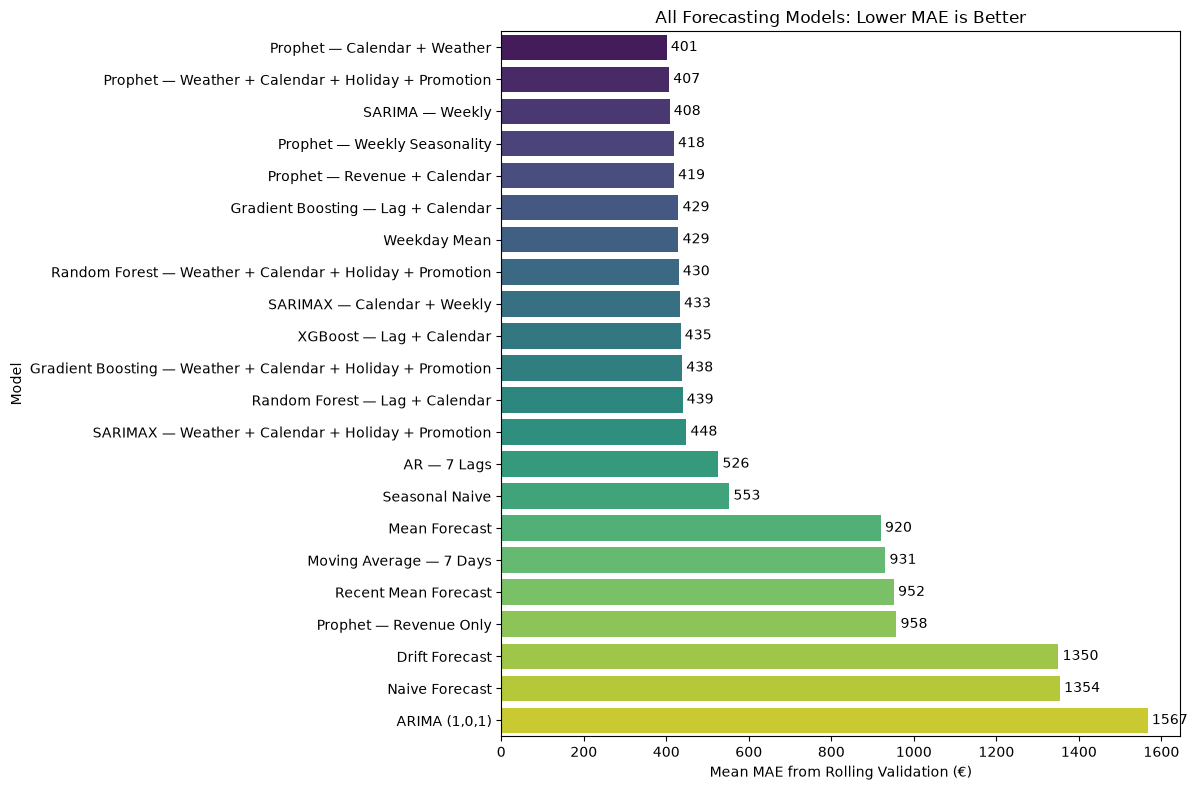

In [39]:
from matplotlib.container import BarContainer

# ==================================================
# VISUALIZE Final Model Comparision with MAE metrics
# ==================================================

plt.figure(figsize=(12, 8))

a= sns.barplot(
    data=comparison_table.sort_values("MAE (€)"),
    x="MAE (€)",
    y="Model",
    hue="Model",
    legend=False,
    palette="viridis"
)

plt.title("All Forecasting Models: Lower MAE is Better")
plt.xlabel("Mean MAE from Rolling Validation (€)")
plt.ylabel("Model")
for container in a.containers:
    if isinstance(container, BarContainer):
        a.bar_label(container, fmt="%.0f", padding=3)
plt.tight_layout()
plt.show()

```Prophet is the selected forecasting model, specifically the Prophet — Calendar + Weather```

Selected model:

Prophet — Calendar + Weather

Features:

- Weekly seasonality
- Calendar/business effects:
    * is_weekend
    * is_holiday
    * is_promo_day
- Weather:
    * temperature_avg_c
    * precipitation_mm
    * is_rainy

# 13. MODEL EVALUATION with test data

In [40]:
# ============================================================
# MODEL 1 — PROPHET: CALENDAR + WEATHER
# ============================================================

test_pred_prophet_weather = prophet_external_forecast(
    history=train,
    valid=test,
    regressors=[
        "is_weekend",
        "is_holiday",
        "is_promo_day",
        "temperature_avg_c",
        "precipitation_mm",
        "is_rainy"
    ],
    weekly_seasonality=True
)

# ============================================================
# MODEL 2 — PROPHET: FULL WEATHER + CALENDAR
# ============================================================

test_pred_prophet_full = weather_prophet_forecast(
    history=train,
    forecast_dates=test["date"]
)

# ============================================================
# MODEL 3 — SARIMA: WEEKLY SEASONALITY
# ============================================================

test_pred_sarima = sarima_forecast(
    history=train,
    forecast_dates=test["date"]
)



12:03:17 - cmdstanpy - INFO - Chain [1] start processing
12:03:17 - cmdstanpy - INFO - Chain [1] done processing
12:03:17 - cmdstanpy - INFO - Chain [1] start processing
12:03:18 - cmdstanpy - INFO - Chain [1] done processing


In [41]:
# ============================================================
# FINAL TEST SET COMPARISON
# ============================================================

test_results = []

predictions = {
    "Prophet — Calendar + Weather": test_pred_prophet_weather,
    "Prophet — Weather + Calendar + Holiday + Promotion": test_pred_prophet_full,
    "SARIMA — Weekly": test_pred_sarima,
}

for model_name, predictions_array in predictions.items():

    metrics = calculate_metrics(
        test["revenue"].to_numpy(),
        predictions_array
    )

    test_results.append({
        "Model": model_name,
        "Test MAE": metrics["MAE"],
        "Test RMSE": metrics["RMSE"],
        "Test MAPE (%)": metrics["MAPE (%)"],
    })

test_results_df = (
    pd.DataFrame(test_results)
    .sort_values("Test MAE")
    .reset_index(drop=True)
)

test_results_df.round(2)

,Model,Test MAE,Test RMSE,Test MAPE (%)
0,Prophet — Calendar + Weather,344.20,445.67,13.97
1,Prophet — Weather + Calendar + Holiday + Promo...,358.28,455.71,14.99
2,SARIMA — Weekly,409.68,529.00,17.06


```On the final Oct–Dec 2025 test period, Prophet — Calendar + Weather achieved a Test MAE of €344.20, compared with €400.86 during rolling validation.```

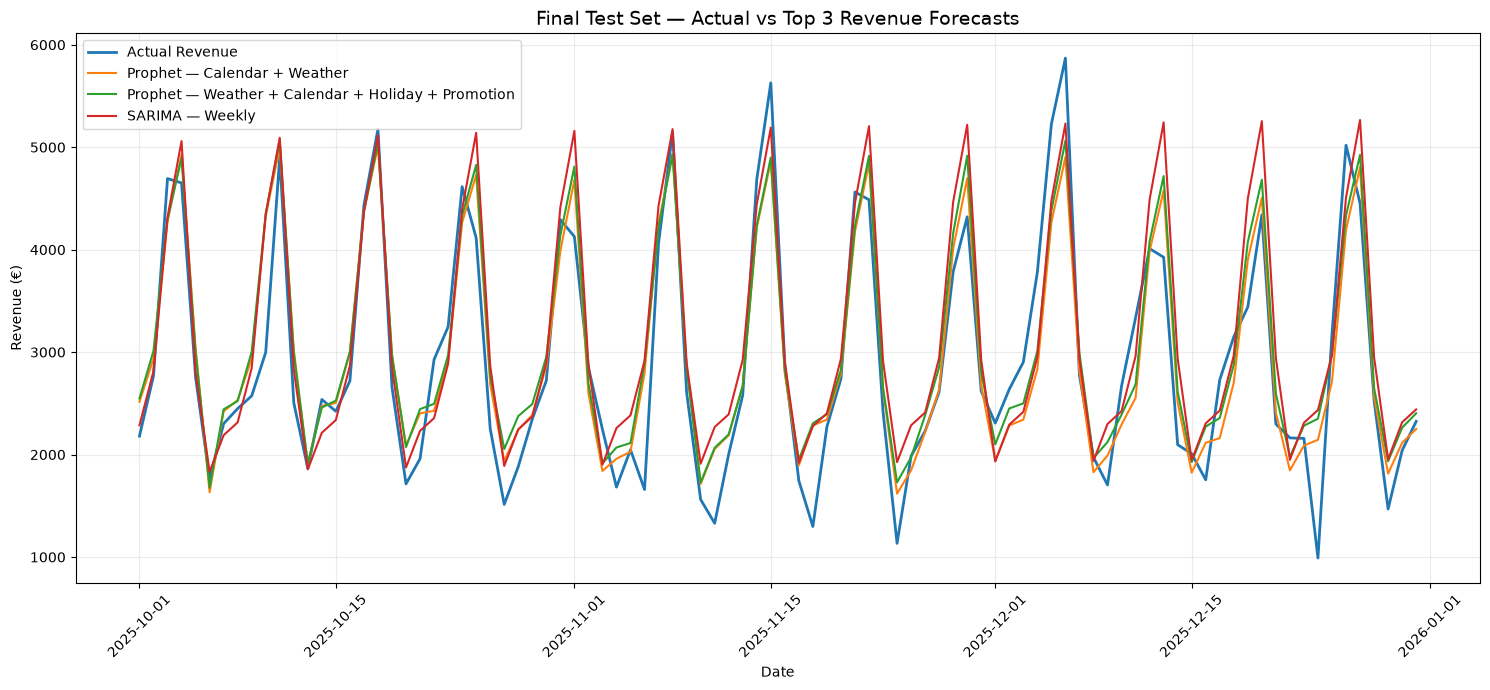

In [42]:
# ============================================================
# Visualisation — ACTUAL VS TOP 3 FORECASTS
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(15, 7))

# Actual revenue
plt.plot(
    test["date"],
    test["revenue"],
    label="Actual Revenue",
    linewidth=2
)

# Model 1 — selected model
plt.plot(
    test["date"],
    test_pred_prophet_weather,
    label="Prophet — Calendar + Weather"
)

# Model 2
plt.plot(
    test["date"],
    test_pred_prophet_full,
    label="Prophet — Weather + Calendar + Holiday + Promotion"
)

# Model 3
plt.plot(
    test["date"],
    test_pred_sarima,
    label="SARIMA — Weekly"
)

plt.title(
    "Final Test Set — Actual vs Top 3 Revenue Forecasts",
    fontsize=14
)

plt.xlabel("Date")
plt.ylabel("Revenue (€)")

plt.legend()
plt.xticks(rotation=45)

plt.grid(alpha=0.25)
plt.tight_layout()

plt.show()

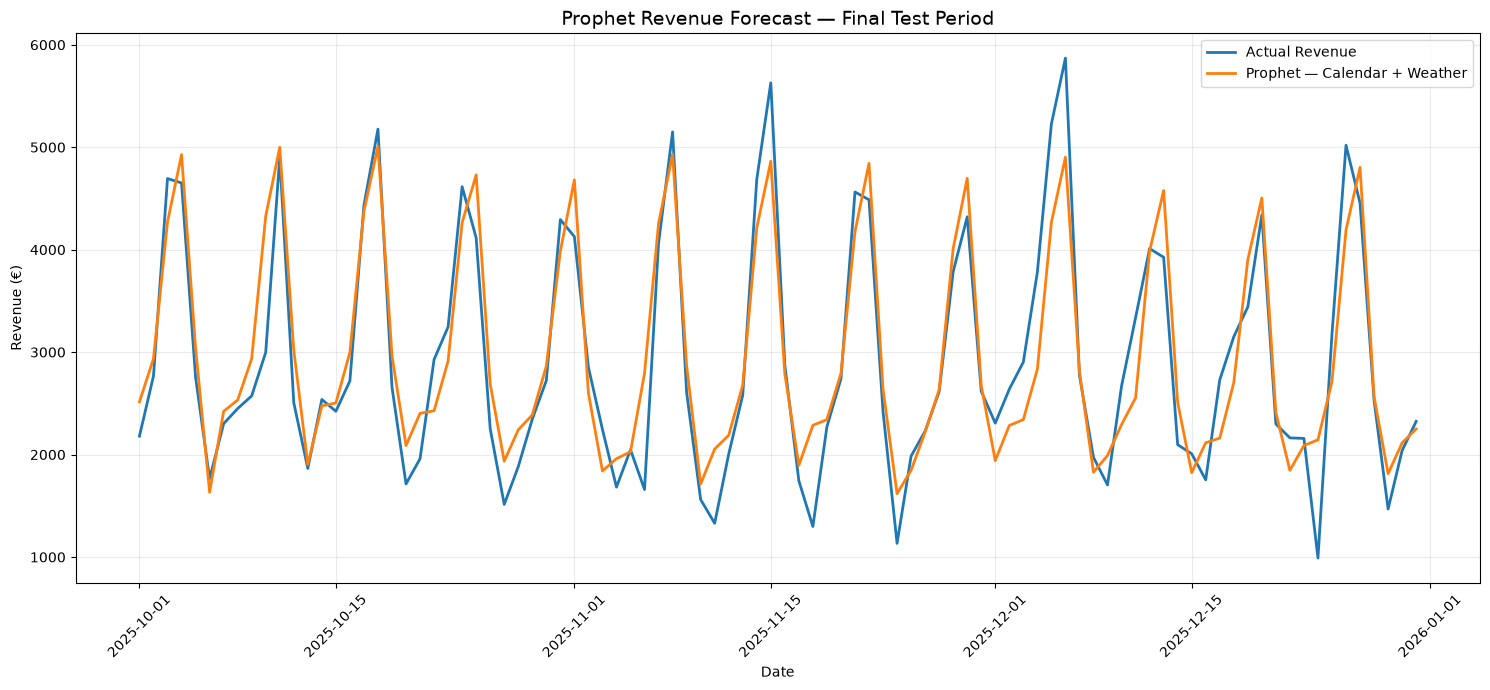

In [43]:
# ============================================================
# FINAL SELECTED MODEL — ACTUAL VS PREDICTED REVENUE
# ============================================================

plt.figure(figsize=(15, 7))

plt.plot(
    test["date"],
    test["revenue"],
    label="Actual Revenue",
    linewidth=2
)

plt.plot(
    test["date"],
    test_pred_prophet_weather,
    label="Prophet — Calendar + Weather",
    linewidth=2
)

plt.title(
    "Prophet Revenue Forecast — Final Test Period",
    fontsize=14
)

plt.xlabel("Date")
plt.ylabel("Revenue (€)")

plt.legend()
plt.xticks(rotation=45)

plt.grid(alpha=0.25)
plt.tight_layout()

plt.show()

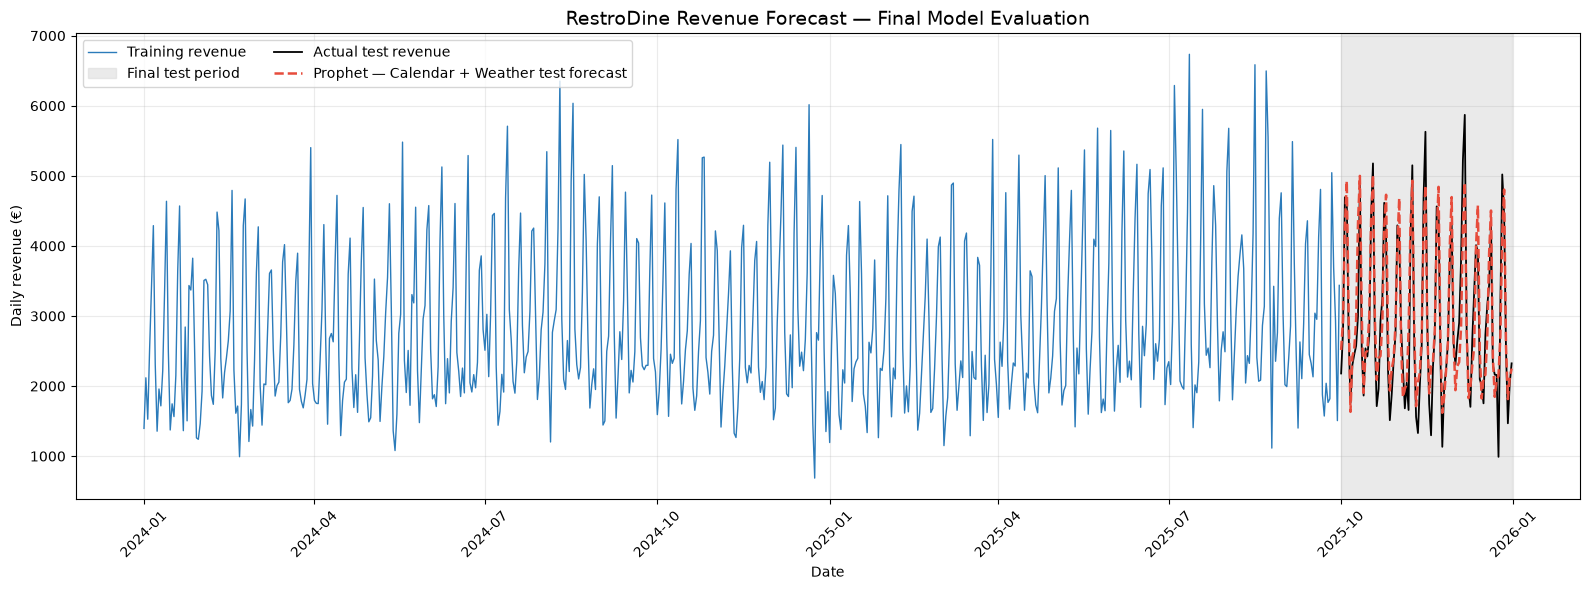

In [44]:
# ============================================================
# FINAL MODEL EVALUATION — TRAINING AND TEST PERIOD
# ============================================================

plt.figure(figsize=(16, 6))

# Training revenue
plt.plot(
    train["date"],
    train["revenue"],
    color="#2b7bba",
    linewidth=1,
    label="Training revenue"
)

# Final test period
plt.axvspan(
    test["date"].iloc[0],
    test["date"].iloc[-1],
    color="#d9d9d9",
    alpha=0.55,
    label="Final test period"
)

# Actual test revenue
plt.plot(
    test["date"],
    test["revenue"],
    color="black",
    linewidth=1.3,
    label="Actual test revenue"
)

# Selected model test forecast
plt.plot(
    test["date"],
    test_pred_prophet_weather,
    color="#e74c3c",
    linestyle="--",
    linewidth=1.8,
    label="Prophet — Calendar + Weather test forecast"
)

plt.title(
    "RestroDine Revenue Forecast — Final Model Evaluation",
    fontsize=14
)

plt.xlabel("Date")
plt.ylabel("Daily revenue (€)")

plt.legend(
    loc="upper left",
    ncol=2
)

plt.xticks(rotation=45)

plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

# 14. Live Weather API for Future Predictions

In [45]:
# ============================================================
# LIVE FORECAST CONFIGURATION
# ============================================================

# Set these to the restaurant's actual location before creating a real future forecast.
RESTAURANT_LATITUDE = 51.4324
RESTAURANT_LONGITUDE = 7.00435

# Planned business events
# Planned restaurant promotions for the forecast period.
# Add dates here when promotions are known.
PLANNED_PROMOTION_DATES = []  # Example: ["2026-01-10", "2026-01-17"]


# ============================================================
# NORTH RHINE-WESTPHALIA PUBLIC HOLIDAYS
# ============================================================

from dateutil.easter import easter


def get_nrw_public_holidays(year):
    """
    Return statutory public holidays for North Rhine-Westphalia.
    """

    easter_sunday = pd.Timestamp(
        easter(year)
    )

    holidays = {
        pd.Timestamp(year, 1, 1): "New Year's Day",
        easter_sunday - pd.Timedelta(days=2): "Good Friday",
        easter_sunday + pd.Timedelta(days=1): "Easter Monday",
        easter_sunday + pd.Timedelta(days=39): "Ascension Day",
        easter_sunday + pd.Timedelta(days=50): "Whit Monday",
        easter_sunday + pd.Timedelta(days=60): "Corpus Christi",
        pd.Timestamp(year, 5, 1): "Labour Day",
        pd.Timestamp(year, 10, 3): "German Unity Day",
        pd.Timestamp(year, 11, 1): "All Saints' Day",
        pd.Timestamp(year, 12, 25): "Christmas Day",
        pd.Timestamp(year, 12, 26): "Boxing Day",
    }

    return holidays

# ============================================================
# FETCH DAILY RAW WEATHER FROM OPEN-METEO
# ============================================================

def fetch_openmeteo_daily_weather(latitude, longitude, start_date, end_date):
    url = "https://api.open-meteo.com/v1/forecast"
    params = {
        "latitude": latitude,
        "longitude": longitude,
        "daily":("temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum"),
        "timezone": "Europe/Berlin",
        "start_date": (pd.Timestamp(start_date).date().isoformat()),
        "end_date": (pd.Timestamp(end_date).date().isoformat()),
    }
    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()
    daily = response.json()["daily"]
    weather = pd.DataFrame({
        "date": pd.to_datetime(daily["time"]),
        "temperature_avg_c": daily["temperature_2m_mean"],
        "temp_max_c": daily["temperature_2m_max"],
        "temp_min_c": daily["temperature_2m_min"],
        "precipitation_mm": daily["precipitation_sum"],
    })
    
    return weather

In [46]:
# ============================================================
# SELECTED PROPHET — FUTURE FEATURES
# ============================================================

SELECTED_PROPHET_REGRESSORS = [
    "is_weekend",
    "is_holiday",
    "is_promo_day",
    "temperature_avg_c",
    "precipitation_mm",
    "is_rainy"
]
RAIN_THRESHOLD_MM=1

def build_selected_prophet_future_features(weather):
    weather = weather.copy()
    weather["date"] = pd.to_datetime(weather["date"])
    # Calendar
    weather["is_weekend"] = (weather["date"].dt.dayofweek >= 5).astype(int)
    # Rain
    weather["is_rainy"] = (weather["precipitation_mm"] >= RAIN_THRESHOLD_MM).astype(int)
    # Drop rows with missing critical weather values if not available from the API
    weather = weather.dropna(subset=["temperature_avg_c", "precipitation_mm"])
    # NRW public holidays
    holiday_lookup = {}
    years = weather["date"].dt.year.unique()
    for year in years:
        holiday_lookup.update(
            get_nrw_public_holidays(int(year)))
    weather["holiday_name"] = (weather["date"].map(holiday_lookup))
    weather["is_holiday"] = (weather["date"].isin(holiday_lookup.keys())).astype(int)
    # Planned restaurant promotions
    promotion_dates = pd.to_datetime(PLANNED_PROMOTION_DATES)
    weather["is_promo_day"] = (weather["date"].isin(promotion_dates)).astype(int)
    return weather[["date"] + SELECTED_PROPHET_REGRESSORS].copy()

In [47]:
# ============================================================
# SELECTED PROPHET — FINAL PRODUCTION MODEL
# ============================================================

def train_selected_prophet(history):

    history = (
        history
        .sort_values("date")
        .copy()
    )

    prophet_train = (
        history[
            ["date", "revenue"] +
            SELECTED_PROPHET_REGRESSORS
        ]
        .rename(
            columns={
                "date": "ds",
                "revenue": "y"
            }
        )
    )

    model = Prophet(
        weekly_seasonality=True,
        yearly_seasonality=False,
        daily_seasonality=False,
        seasonality_mode="additive",
        interval_width=0.80
    )

    for regressor in SELECTED_PROPHET_REGRESSORS:
        model.add_regressor(regressor)

    model.fit(prophet_train)

    return model

In [48]:
# ============================================================
# SELECTED PROPHET — FUTURE REVENUE FORECAST
# ============================================================

def forecast_selected_prophet(
    model,
    future_features
):

    future = (
        future_features
        .rename(columns={"date": "ds"})
        .copy()
    )

    forecast = model.predict(
        future[
            ["ds"] +
            SELECTED_PROPHET_REGRESSORS
        ]
    )

    result = pd.DataFrame({
        "date": forecast["ds"],
        "forecast_revenue": forecast["yhat"],
        "lower_bound": forecast["yhat_lower"],
        "upper_bound": forecast["yhat_upper"],
    })

    return result

# 15. The Forecast

In [49]:
# ============================================================
# OPERATIONAL FORECAST — NEXT 14 DAYS
# ============================================================

forecast_horizon = 14

forecast_start = (pd.Timestamp.today().normalize() + pd.Timedelta(days=1))

future_dates = pd.date_range(
    start=forecast_start,
    periods=forecast_horizon,
    freq="D"
)

print("Operational forecast period:")
print(
    future_dates.min().date(),
    "to",
    future_dates.max().date()
)


Operational forecast period:
2026-11-06 to 2026-11-19


In [50]:
# ============================================================
# OPERATIONAL FORECAST — HISTORY GAP CHECK
# ============================================================
last_observed_date = (df["date"] .max() )
forecast_start = (future_dates.min())
history_gap_days = (forecast_start - last_observed_date).days - 1
print( "Last observed revenue:", last_observed_date.date() )
print( "Forecast starts:", forecast_start.date() )
print( "Days without observed revenue:", history_gap_days )

Last observed revenue: 2025-12-31
Forecast starts: 2026-11-06
Days without observed revenue: 309


In [51]:
# ============================================================
# HISTORY GAP — INTERPRETATION
# ============================================================

if history_gap_days > 0:
    print(
        "\nNOTE: The current historical revenue data does not "
        "extend continuously to the operational forecast date."
    )
    print(
        "The model can generate the forecast mathematically, "
        "but the Streamlit application should use updated/"
        "simulated operational data before generating a live forecast."
    )
else:
    print( "\nHistorical revenue is continuous up to the " "operational forecast start." )


NOTE: The current historical revenue data does not extend continuously to the operational forecast date.
The model can generate the forecast mathematically, but the Streamlit application should use updated/simulated operational data before generating a live forecast.


Our historical revenue dataset ends on 31 December 2025, while the operational forecast is being generated for November/December 2026

-----------------------------------------------
```COMPLETE 14-DAY OPERATIONAL FORECAST PIPELINE```


In [52]:
# ============================================================
# OPERATIONAL FORECAST — FETCH FUTURE WEATHER
# ============================================================

# 1. Fetch future weather
api_weather = fetch_openmeteo_daily_weather(
    RESTAURANT_LATITUDE,
    RESTAURANT_LONGITUDE,
    future_dates.min(),
    future_dates.max()
)

display(api_weather)

,date,temperature_avg_c,temp_max_c,temp_min_c,precipitation_mm
0,2026-11-06,6.3,11.6,2.6,0.0
1,2026-11-07,6.3,10.4,3.0,0.0
2,2026-11-08,6.8,8.6,5.3,0.0
3,2026-11-09,6.1,8.6,2.9,0.0
4,2026-11-10,3.8,8.4,-0.1,0.0
5,2026-11-11,5.2,10.4,0.8,0.0
6,2026-11-12,9.8,12.2,6.3,1.0
7,2026-11-13,6.6,11.2,3.4,8.8
8,2026-11-14,3.6,7.4,1.0,2.8
9,2026-11-15,2.6,6.5,0.0,0.0


In [53]:
# ============================================================
# OPERATIONAL FORECAST — BUILD MODEL FEATURES
# ============================================================

# 2. Build the exact features required by the selected model
future_features = build_selected_prophet_future_features(api_weather)
display(future_features)

,date,is_weekend,is_holiday,is_promo_day,temperature_avg_c,precipitation_mm,is_rainy
0,2026-11-06,0,0,0,6.3,0.0,0
1,2026-11-07,1,0,0,6.3,0.0,0
2,2026-11-08,1,0,0,6.8,0.0,0
3,2026-11-09,0,0,0,6.1,0.0,0
4,2026-11-10,0,0,0,3.8,0.0,0
5,2026-11-11,0,0,0,5.2,0.0,0
6,2026-11-12,0,0,0,9.8,1.0,1
7,2026-11-13,0,0,0,6.6,8.8,1
8,2026-11-14,1,0,0,3.6,2.8,1
9,2026-11-15,1,0,0,2.6,0.0,0


In [54]:
# ============================================================
# TRAIN FINAL PRODUCTION MODEL
# ============================================================

# 3. Train the selected model on ALL historical data
production_model = train_selected_prophet(df)
print("Production model trained through:",df["date"].max().date())

12:03:20 - cmdstanpy - INFO - Chain [1] start processing
12:03:20 - cmdstanpy - INFO - Chain [1] done processing


Production model trained through: 2025-12-31


In [55]:
# ============================================================
# GENERATE 14-DAY OPERATIONAL REVENUE FORECAST
# ============================================================

# 4. GENERATE 14-DAY OPERATIONAL REVENUE FORECAST
future_forecast = forecast_selected_prophet( production_model, future_features )

display(future_forecast.round(2))

/var/folders/lk/_pf4928d6_x99xld7btjlldc0000gn/T/ipykernel_36529/3573615749.py:8: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(future_forecast.round(2))


,date,forecast_revenue,lower_bound,upper_bound
0,2026-11-06,4327.06,3727.40,4905.30
1,2026-11-07,4982.97,4391.47,5601.87
2,2026-11-08,2930.35,2326.11,3523.75
3,2026-11-09,2016.22,1416.44,2666.78
4,2026-11-10,2299.09,1692.30,2864.02
5,2026-11-11,2443.72,1813.43,3031.37
6,2026-11-12,2818.05,2220.99,3424.98
7,2026-11-13,4102.56,3499.97,4707.61
8,2026-11-14,4747.57,4124.23,5375.92
9,2026-11-15,2865.10,2243.05,3533.19


### Operational Forecast Interpretation

The selected Prophet model was retrained on the complete historical revenue dataset and used to generate a 14-day operational forecast using future weather, calendar, holiday and promotion information.

The historical dataset ends on 31 December 2025, while the operational forecast represents a future 2026 scenario. Therefore, this forecast demonstrates the production forecasting pipeline rather than providing a measured accuracy result for the 2026 forecast period, since actual 2026 revenue is not yet available in the dataset.

In the final Streamlit application, the same forecasting pipeline will be applied to the latest available operational data and refreshed as new revenue observations become available.

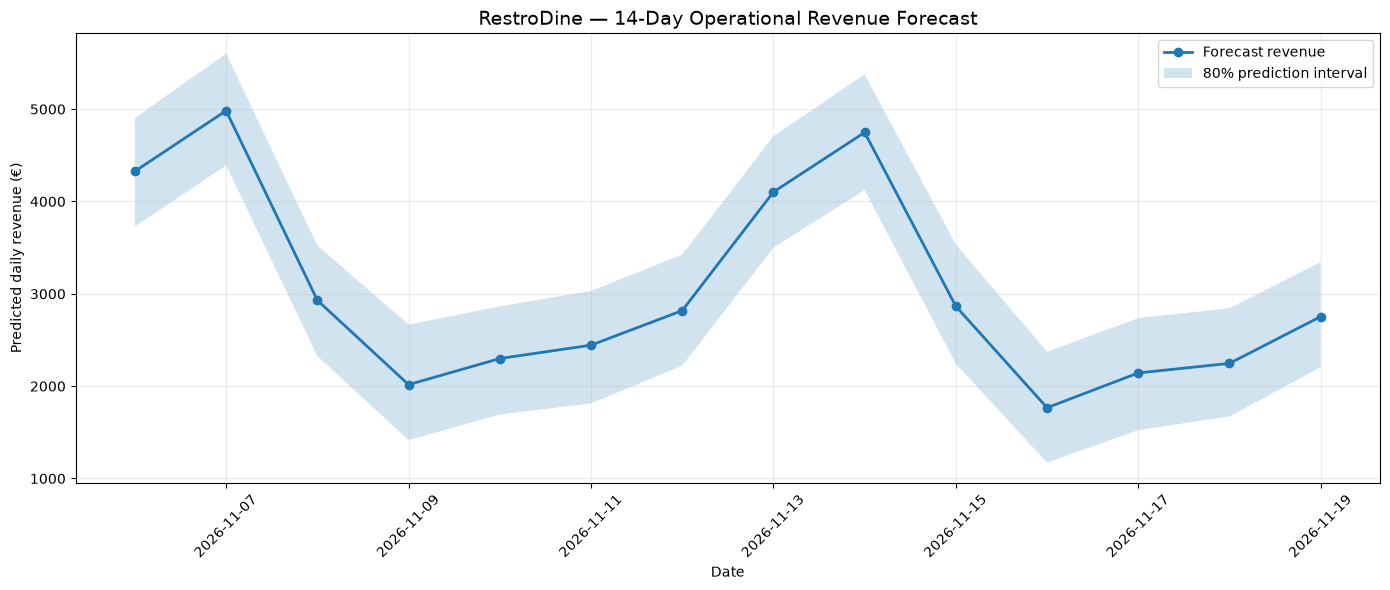

In [56]:
# ============================================================
# OPERATIONAL FORECAST — NEXT 14 DAYS
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    future_forecast["date"],
    future_forecast["forecast_revenue"],
    marker="o",
    linewidth=2,
    label="Forecast revenue"
)

plt.fill_between(
    future_forecast["date"],
    future_forecast["lower_bound"],
    future_forecast["upper_bound"],
    alpha=0.20,
    label="80% prediction interval"
)

plt.title(
    "RestroDine — 14-Day Operational Revenue Forecast",
    fontsize=14
)

plt.xlabel("Date")
plt.ylabel("Predicted daily revenue (€)")

plt.xticks(rotation=45)

plt.legend()

plt.grid(alpha=0.25)

plt.tight_layout()

plt.show()

# 16. Save the Model

In [57]:
# ============================================================
# OPERATIONAL FORECAST — QUALITY CHECK
# ============================================================

print("Forecast rows:", len(future_forecast))

print( "Expected rows:", forecast_horizon )

print( "Missing predictions:", future_forecast["forecast_revenue"].isna().sum() )

print( "Negative predictions:", (future_forecast["forecast_revenue"] < 0).sum() )

print( "Forecast start:", future_forecast["date"].min().date() )

print( "Forecast end:", future_forecast["date"].max().date() )

print( "Minimum forecast revenue:", round(future_forecast["forecast_revenue"].min(), 2) )

print( "Maximum forecast revenue:", round(future_forecast["forecast_revenue"].max(), 2) )


Forecast rows: 14
Expected rows: 14
Missing predictions: 0
Negative predictions: 0
Forecast start: 2026-11-06
Forecast end: 2026-11-19
Minimum forecast revenue: 1766.49
Maximum forecast revenue: 4982.97


In [58]:
# ============================================================
# SAVE FINAL PRODUCTION MODEL
# ============================================================

model_dir = Path("../models")

model_dir.mkdir( parents=True, exist_ok=True )

model_path = ( model_dir / "restrodine_prophet_calendar_weather.json" ) # The actual trained Prophet model

with open( model_path, "w" ) as file: file.write( model_to_json( production_model ) )

print( "Model saved to:", model_path )

Model saved to: ../models/restrodine_prophet_calendar_weather.json


In [59]:
# ============================================================
# SAVE PRODUCTION MODEL METADATA
# ============================================================
metadata_dir = Path("../metadata")  

model_metadata = {
    "model": "Prophet — Calendar + Weather",
    "weekly_seasonality": True,
    "yearly_seasonality": False,
    "daily_seasonality": False,
    "seasonality_mode": "additive",
    "regressors": SELECTED_PROPHET_REGRESSORS,
    "rain_threshold_mm": RAIN_THRESHOLD_MM,
    "location": {
        "latitude": RESTAURANT_LATITUDE,
        "longitude": RESTAURANT_LONGITUDE,
        "region": "North Rhine-Westphalia, Germany"
    },
    "training_start": str( df["date"].min().date() ),
    "training_end": str( df["date"].max().date() )
}

metadata_path = ( metadata_dir / "restrodine_prophet_calendar_weather_metadata.json" ) # Documentation about how the model was trained

with open( metadata_path, "w" ) as file:
    json.dump( model_metadata, file, indent=4 )

print( "Metadata saved to:", metadata_path )

Metadata saved to: ../metadata/restrodine_prophet_calendar_weather_metadata.json


In [60]:
# ============================================================
# SAVE OPERATIONAL REVENUE FORECAST
# ============================================================

# Create output directory if it does not already exist
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Ensure date is stored consistently
future_forecast["date"] = pd.to_datetime( future_forecast["date"] )

# Save forecast
future_forecast_path = ( output_dir / "revenue_forecast_next_14_days.csv" )

future_forecast.to_csv( future_forecast_path, index=False )
# ============================================================
# VERIFY SAVED OUTPUT
# ============================================================

print("Revenue forecast saved successfully.")
print(f"File: {future_forecast_path}")


Revenue forecast saved successfully.
File: ../outputs/revenue_forecast_next_14_days.csv


In [61]:
# ============================================================
# REVENUE FORECASTING — FINAL SUMMARY
# ============================================================

print("=" * 65)
print("RESTRODINE REVENUE FORECASTING — FINAL SUMMARY")
print("=" * 65)

print("\nSelected model:")
print("Prophet — Calendar + Weather")

print("\nModel regressors:")
for regressor in SELECTED_PROPHET_REGRESSORS:
    print(" -", regressor)

print("\nHistorical data:")
print(
    df["date"].min().date(),
    "to",
    df["date"].max().date()
)

print("\nOperational forecast:")
print(
    future_dates.min().date(),
    "to",
    future_dates.max().date()
)

print("\nForecast horizon:")
print(forecast_horizon, "days")

print("\nHistory gap:")
print(history_gap_days, "days")

print("\nProduction model:")
print(model_path)

print("\nModel metadata:")
print(metadata_path)


print("\nModel output:")
print(future_forecast_path)

print("\nForecast rows generated:")
print(len(future_forecast))

print("\nRevenue forecasting pipeline complete.")

RESTRODINE REVENUE FORECASTING — FINAL SUMMARY

Selected model:
Prophet — Calendar + Weather

Model regressors:
 - is_weekend
 - is_holiday
 - is_promo_day
 - temperature_avg_c
 - precipitation_mm
 - is_rainy

Historical data:
2024-01-01 to 2025-12-31

Operational forecast:
2026-11-06 to 2026-11-19

Forecast horizon:
14 days

History gap:
309 days

Production model:
../models/restrodine_prophet_calendar_weather.json

Model metadata:
../metadata/restrodine_prophet_calendar_weather_metadata.json

Model output:
../outputs/revenue_forecast_next_14_days.csv

Forecast rows generated:
14

Revenue forecasting pipeline complete.
